# Aprendizagem Automática (APRAU) - Trabalho de Grupo

**Mestrado em Engenharia Informática · ISEP · 2026/2027**

**Grupo 14**

|      Nome         | Nº de aluno |
|-------------------|-------------|
| Ellah Fleischmann |   1231478   |
|   Inês Martinho   |   1230806   |
#
**Docente (PL):** Elsa Ferreira Gomes · **Turma:** M1A

---

### Índice
1. Introdução
2. Preparação do ambiente e carregamento dos dados
3. Análise Exploratória de Dados (EDA)
4. Regressão
5. Classificação
6. Seleção de Variáveis (Ridge e Lasso)
7. Conclusões
8. Referências

## 1. Introdução

Este trabalho aplica diferentes métodos de aprendizagem automática a um conjunto de dados clínico multi-doença, com o objetivo de analisar o comportamento dos modelos e interpretar criticamente os resultados.

O dataset provém de um *data warehouse* (DW) médico consolidado, desenhado para estudar padrões de comorbilidade em doenças cardiometabólicas crónicas. Cada registo representa o perfil de um doente, com variáveis demográficas, antropométricas, de estilo de vida e biomarcadores laboratoriais, e tem duas variáveis alvo:

- `target_class` (categórica): categoria de diagnóstico clínico, usada na **classificação**;
- `target_regression` (contínua): medição laboratorial, usada na **regressão**.

O subconjunto atribuído ao grupo 14 tem 2000 registos e três classes de diagnóstico (DI, HT e HT_HY), com forte desbalanceamento entre elas.

**Estrutura do trabalho**

| Secção | Conteúdo |
|--------|----------|
| EDA | Estatística descritiva, análise univariada e bivariada; deteção de variáveis constantes, redundantes ou pouco informativas |
| Regressão | Regressão linear simples e múltipla, comparadas com R², MAE e RMSE |
| Classificação | Regressão logística e LDA, com holdout, CV (k=5 e k=10), LOOCV e bootstrap |
| Seleção de variáveis | Ridge e Lasso: todas as variáveis vs. conjunto reduzido |

## 2. Preparação do ambiente e carregamento dos dados

Nesta secção importamos as bibliotecas, fixamos a semente aleatória (para os resultados serem reprodutíveis) e carregamos o dataset. Fazemos ainda uma verificação inicial da dimensão, dos tipos de dados e da distribuição da variável alvo de classificação.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42 # semente usada em todo o trabalho

In [2]:
df = pd.read_csv("../data/dataset_grupo_14.csv")

print(df.shape)
df.head()

(2000, 35)


,age_level,gender,bmi_level,smoking,age,age_normalized,bmi,HbA1c_level,cholesterol,sleep_hours,...,hdl,ldl,education_level,employment_status,systolic_index,calcium_baseline,plasma_value,ldl_alternative,target_regression,target_class
0,Senior,Male,Overweight,Never,82,0.919540,29.20,7.003349,207.00000,8.000000,...,79.000000,160.000000,Primary,Retired,137.000000,9.42,1.094354,128.408780,194.0,DI
1,Senior,Female,Overweight,Never,80,0.896552,27.32,6.500000,224.41791,7.179453,...,64.012168,129.853982,Primary,Retired,136.462389,9.42,1.339049,97.000000,160.0,DI
2,Senior,Male,Normal,Never,73,0.816091,21.10,7.010714,175.00000,5.900000,...,45.000000,106.000000,Secondary,Employed,133.000000,9.42,1.415402,112.000000,104.0,DI
3,Senior,Female,Obese,Former,85,0.954022,34.80,6.865766,163.00000,5.500000,...,98.000000,116.000000,Tertiary,Employed,95.000000,9.42,1.173173,128.585774,195.0,DI
4,Senior,Male,Overweight,Former,69,0.770114,28.90,6.993220,172.00000,6.900000,...,31.000000,97.000000,Tertiary,Retired,128.000000,9.42,1.210187,152.000000,171.0,DI


### 2.1 Estrutura e tipos de dados

Verificamos os tipos de cada coluna e a existência de valores em falta.

In [3]:
df.info()
print("\nValores em falta por coluna:")
print(df.isnull().sum()[df.isnull().sum() > 0])

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 35 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   age_level             2000 non-null   object 
 1   gender                2000 non-null   object 
 2   bmi_level             2000 non-null   object 
 3   smoking               2000 non-null   object 
 4   age                   2000 non-null   int64  
 5   age_normalized        2000 non-null   float64
 6   bmi                   2000 non-null   float64
 7   HbA1c_level           2000 non-null   float64
 8   cholesterol           2000 non-null   float64
 9   sleep_hours           2000 non-null   float64
 10  triglycerides         2000 non-null   float64
 11  physical_activity     2000 non-null   object 
 12  family_history        2000 non-null   object 
 13  stress_level          2000 non-null   object 
 14  low_hdl_cholesterol   2000 non-null   object 
 15  high_ldl_cholesterol 

### 2.2 Distribuição da variável alvo de classificação

Como o enunciado indica que a maioria dos grupos trabalha com um dataset desbalanceado, é importante perceber desde já a proporção de cada classe, pois isso condiciona a escolha das métricas de avaliação.

In [4]:
print(df['target_class'].value_counts())
print()
print(df['target_class'].value_counts(normalize=True).round(3))

target_class
DI       1714
HT        183
HT_HY     103
Name: count, dtype: int64

target_class
DI       0.857
HT       0.092
HT_HY    0.052
Name: proportion, dtype: float64


### 2.3 Separação dos tipos de variáveis

Separamos as variáveis categóricas das numéricas, excluindo os dois alvos, para as reutilizarmos ao longo da análise.

In [5]:
cat_cols = df.select_dtypes(include=['object', 'string']).columns.drop('target_class').tolist()
num_cols = df.select_dtypes(include=['number']).columns.drop('target_regression').tolist()

print(f"Categóricas: ({len(cat_cols)}) {cat_cols}")
print(f"Numéricas: ({len(num_cols)}) {num_cols}")

Categóricas: (12) ['age_level', 'gender', 'bmi_level', 'smoking', 'physical_activity', 'family_history', 'stress_level', 'low_hdl_cholesterol', 'high_ldl_cholesterol', 'sugar_consumption', 'education_level', 'employment_status']
Numéricas: (21) ['age', 'age_normalized', 'bmi', 'HbA1c_level', 'cholesterol', 'sleep_hours', 'triglycerides', 'blood_pressure', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'systolic_index', 'calcium_baseline', 'plasma_value', 'ldl_alternative']


## 3. Análise Exploratória de Dados (EDA)

### 3.1 Estatística descritiva

Começamos por resumir numericamente as variáveis. Para as numéricas, analisamos medidas de tendência central (média, mediana), dispersão (desvio-padrão, quartis, amplitude) e assimetria. Para as categóricas, analisamos a frequência de cada categoria. Esta análise permite detetar à partida variáveis constantes, valores fora do intervalo esperado e possíveis outliers.

In [6]:
desc = df[num_cols].describe().T
desc['skew'] = df[num_cols].skew()
desc['nunique'] = df[num_cols].nunique()
desc.round(3)

,count,mean,std,min,25%,50%,75%,max,skew,nunique
age,2000.0,55.404,20.119,7.000,39.000,58.000,73.000,89.000,-0.200,78
age_normalized,2000.0,0.614,0.231,0.057,0.425,0.644,0.816,1.000,-0.200,141
bmi,2000.0,28.086,7.078,15.000,22.600,27.320,33.590,59.270,0.269,744
HbA1c_level,2000.0,6.710,0.776,3.500,6.592,6.890,7.003,9.000,-0.882,131
cholesterol,2000.0,223.302,36.367,150.000,198.000,224.527,247.000,300.000,0.003,245
sleep_hours,2000.0,6.925,1.514,4.000,5.800,6.985,7.998,10.000,0.033,339
triglycerides,2000.0,172.755,69.580,50.000,120.750,163.000,232.418,400.000,0.341,371
blood_pressure,2000.0,150.213,5.811,120.000,149.008,149.968,151.152,180.000,0.451,159
crp_level,2000.0,7.381,1.420,0.024,7.295,7.458,7.706,14.945,-0.526,289
homocysteine_level,2000.0,12.357,1.449,5.046,12.259,12.417,12.638,19.992,-0.446,289


In [7]:
for col in cat_cols:
    print(f"--- {col} ---")
    print(df[col].value_counts())
    print()

--- age_level ---
age_level
Senior    667
Mature    646
Middle    547
Young     140
Name: count, dtype: int64

--- gender ---
gender
Male      1026
Female     974
Name: count, dtype: int64

--- bmi_level ---
bmi_level
Obese          783
Overweight     517
Normal         514
Underweight    186
Name: count, dtype: int64

--- smoking ---
smoking
Never      744
Former     654
Current    602
Name: count, dtype: int64

--- physical_activity ---
physical_activity
High        810
Moderate    600
Low         590
Name: count, dtype: int64

--- family_history ---
family_history
No     1086
Yes     914
Name: count, dtype: int64

--- stress_level ---
stress_level
Low       709
High      662
Medium    629
Name: count, dtype: int64

--- low_hdl_cholesterol ---
low_hdl_cholesterol
No     1598
Yes     402
Name: count, dtype: int64

--- high_ldl_cholesterol ---
high_ldl_cholesterol
Yes    1023
No      977
Name: count, dtype: int64

--- sugar_consumption ---
sugar_consumption
Low       743
Medium    646


In [8]:
print("Linhas duplicadas:", df.duplicated().sum())
print("\nEstatísticas do alvo de regressão:")
print(df['target_regression'].describe().round(3))

Linhas duplicadas: 0

Estatísticas do alvo de regressão:
count    2000.000
mean      141.429
std        45.440
min        70.000
25%       107.000
50%       140.000
75%       163.000
max       300.000
Name: target_regression, dtype: float64


In [9]:
# Redundância: cópias exatas e correlação
print("ldl == ldl_alternative:", df['ldl'].equals(df['ldl_alternative']))
print("systolic_bp == systolic_index:", df['systolic_bp'].equals(df['systolic_index']))
print("corr(age, age_normalized):", df['age'].corr(df['age_normalized']).round(4))

ldl == ldl_alternative: False
systolic_bp == systolic_index: True
corr(age, age_normalized): 1.0


In [10]:
# Outliers pela regra do IQR (1.5 x IQR)
Q1 = df[num_cols].quantile(0.25)
Q3 = df[num_cols].quantile(0.75)
IQR = Q3 - Q1
fora = (df[num_cols] < Q1 - 1.5 * IQR) | (df[num_cols] > Q3 + 1.5 * IQR)

n_out = fora.sum()
n_out[n_out > 0].sort_values(ascending=False)

HbA1c_level           330
crp_level             294
blood_pressure        262
homocysteine_level    246
systolic_bp           131
systolic_index        131
diastolic_bp           65
salt_intake            48
hdl                    34
plasma_value           19
bmi                     9
triglycerides           1
alcohol_intake          1
dtype: int64

**Outliers**

As variáveis com mais outliers (`HbA1c_level`, `crp_level`, `blood_pressure`, `homocysteine_level`) têm um IQR muito estreito: metade dos valores está concentrada perto da média (ex.: `blood_pressure` entre 149 e 151). Isto indica que muitos valores foram provavelmente imputados com a média, pelo que os "outliers" detetados são, em grande parte, os valores reais medidos. Por esta razão **não removemos outliers**.

In [11]:
diff = (df['ldl'] - df['ldl_alternative']).abs()
print("Linhas diferentes:", (diff > 0).sum())
print("Mesmos valores, ordem diferente:", np.allclose(np.sort(df['ldl']), np.sort(df['ldl_alternative'])))
print("Correlação:", df['ldl'].corr(df['ldl_alternative']).round(4))

Linhas diferentes: 1985
Mesmos valores, ordem diferente: True
Correlação: -0.0154


**Conclusões da estatística descritiva**

- Não existem valores em falta nem linhas duplicadas.
- `calcium_baseline` é **constante** (desvio-padrão 0; valor único 9,42), logo não tem informação → removida.
- `systolic_index` é uma **cópia exata** de `systolic_bp` → removida.
- `age_normalized` é uma transformação linear de `age` (correlação = 1) → redundante, removida.
- `ldl_alternative` contém os mesmos valores de `ldl` mas por outra ordem (correlação ≈ −0,015): é uma permutação aleatória, sem relação com o doente → ruído, removida.
- `age_level` e `bmi_level` são derivadas de `age` e `bmi`; avaliamos na análise bivariada se acrescentam informação.
- A classe alvo está muito desbalanceada (DI 85,7%, HT 9,2%, HT_HY 5,2%), o que obriga a usar métricas como F1-macro e recall por classe, e não apenas accuracy.

### 3.2 Análise univariada

Analisamos a distribuição de cada variável individualmente: histogramas para as numéricas e gráficos de barras para as categóricas. O objetivo é perceber a forma das distribuições (simétricas, assimétricas, multimodais), identificar valores atípicos e categorias muito raras, e confirmar visualmente os problemas detetados na estatística descritiva.

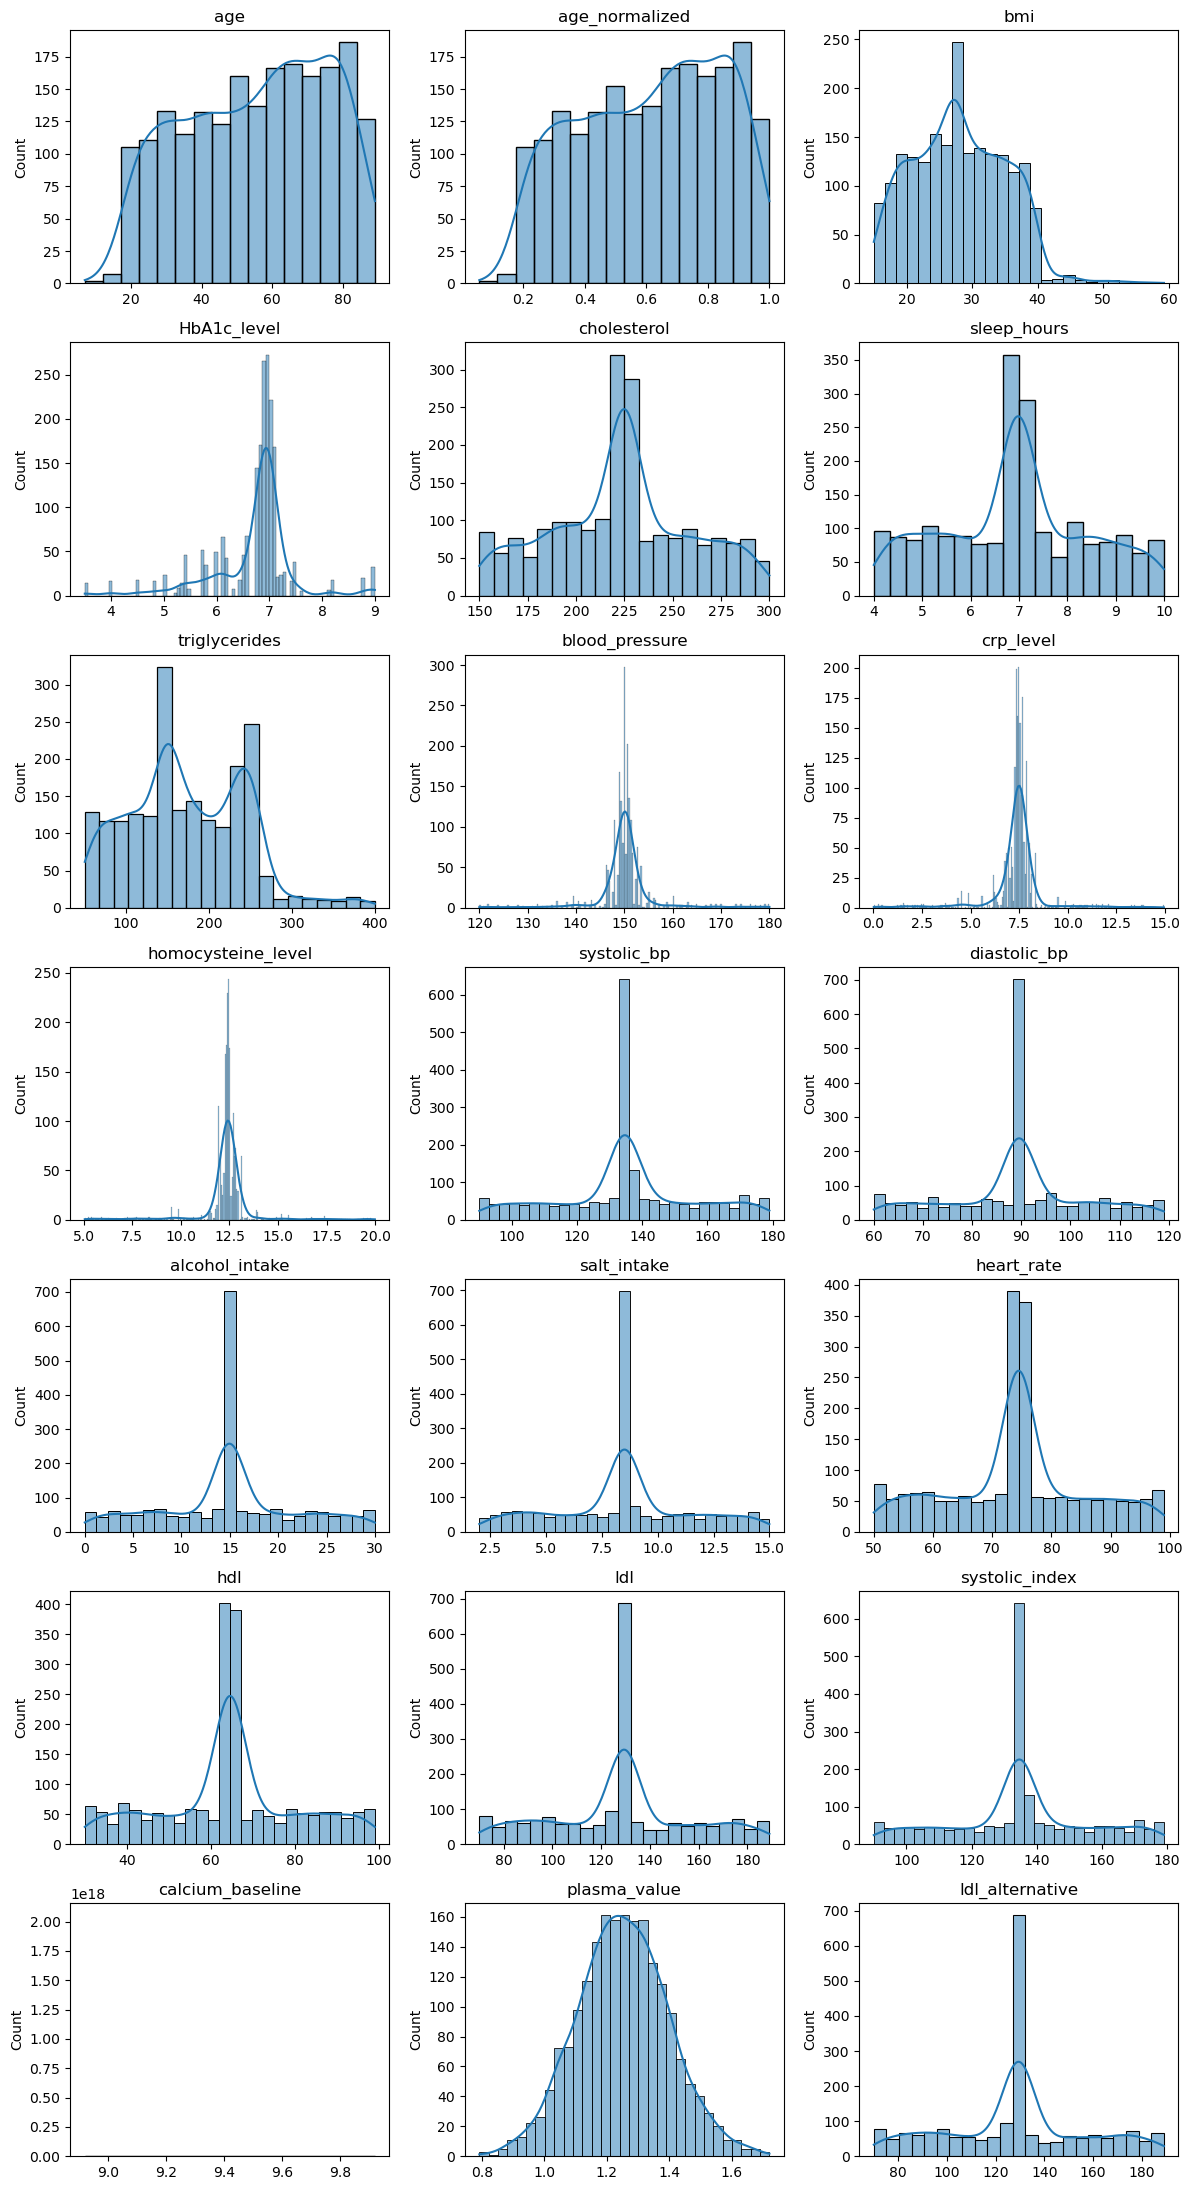

In [12]:
fig, axes = plt.subplots(7, 3, figsize=(12, 22))
for ax, col in zip(axes.ravel(), num_cols):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(col)
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

**Interpretação: variáveis numéricas**

- **Valores imputados:** a maioria das variáveis numéricas (`bmi`, `cholesterol`, `sleep_hours`, `systolic_bp`, `diastolic_bp`, `alcohol_intake`, `salt_intake`, `heart_rate`, `hdl`, `ldl`) apresenta um pico muito acentuado num único valor central, que chega a concentrar cerca de 700 doentes (≈35% dos dados). Fora desse pico, a distribuição é aproximadamente **uniforme**. Este padrão indica que os valores em falta foram preenchidos com a média. A assimetria próxima de 0 destas variáveis resulta de o pico estar no centro, e não de terem uma distribuição normal.
- `blood_pressure`, `crp_level`, `homocysteine_level` e `HbA1c_level` estão muito concentradas num intervalo estreito, com caudas longas e pouco povoadas. É por isso que a regra do IQR deteta tantos outliers nestas variáveis.
- `HbA1c_level` tem assimetria negativa (−0,88): a maioria dos valores está perto de 7 e a cauda estende-se para valores mais baixos (até 3,5).
- `triglycerides` é **bimodal**, com picos perto de 150 e de 240, e uma cauda até 400.
- `age` está concentrada em idades mais elevadas, com muito poucos doentes abaixo dos 20 anos.
- `plasma_value` é a única variável com distribuição aproximadamente **normal** e tem um valor diferente para cada doente. Pode tratar-se de ruído, o que será verificado na análise bivariada.
- `calcium_baseline` não é representada no histograma por ser **constante** (valor único 9,42).
- `age` e `age_normalized` têm a mesma forma, tal como `systolic_bp` e `systolic_index`, e `ldl` e `ldl_alternative`, o que confirma a redundância já identificada.

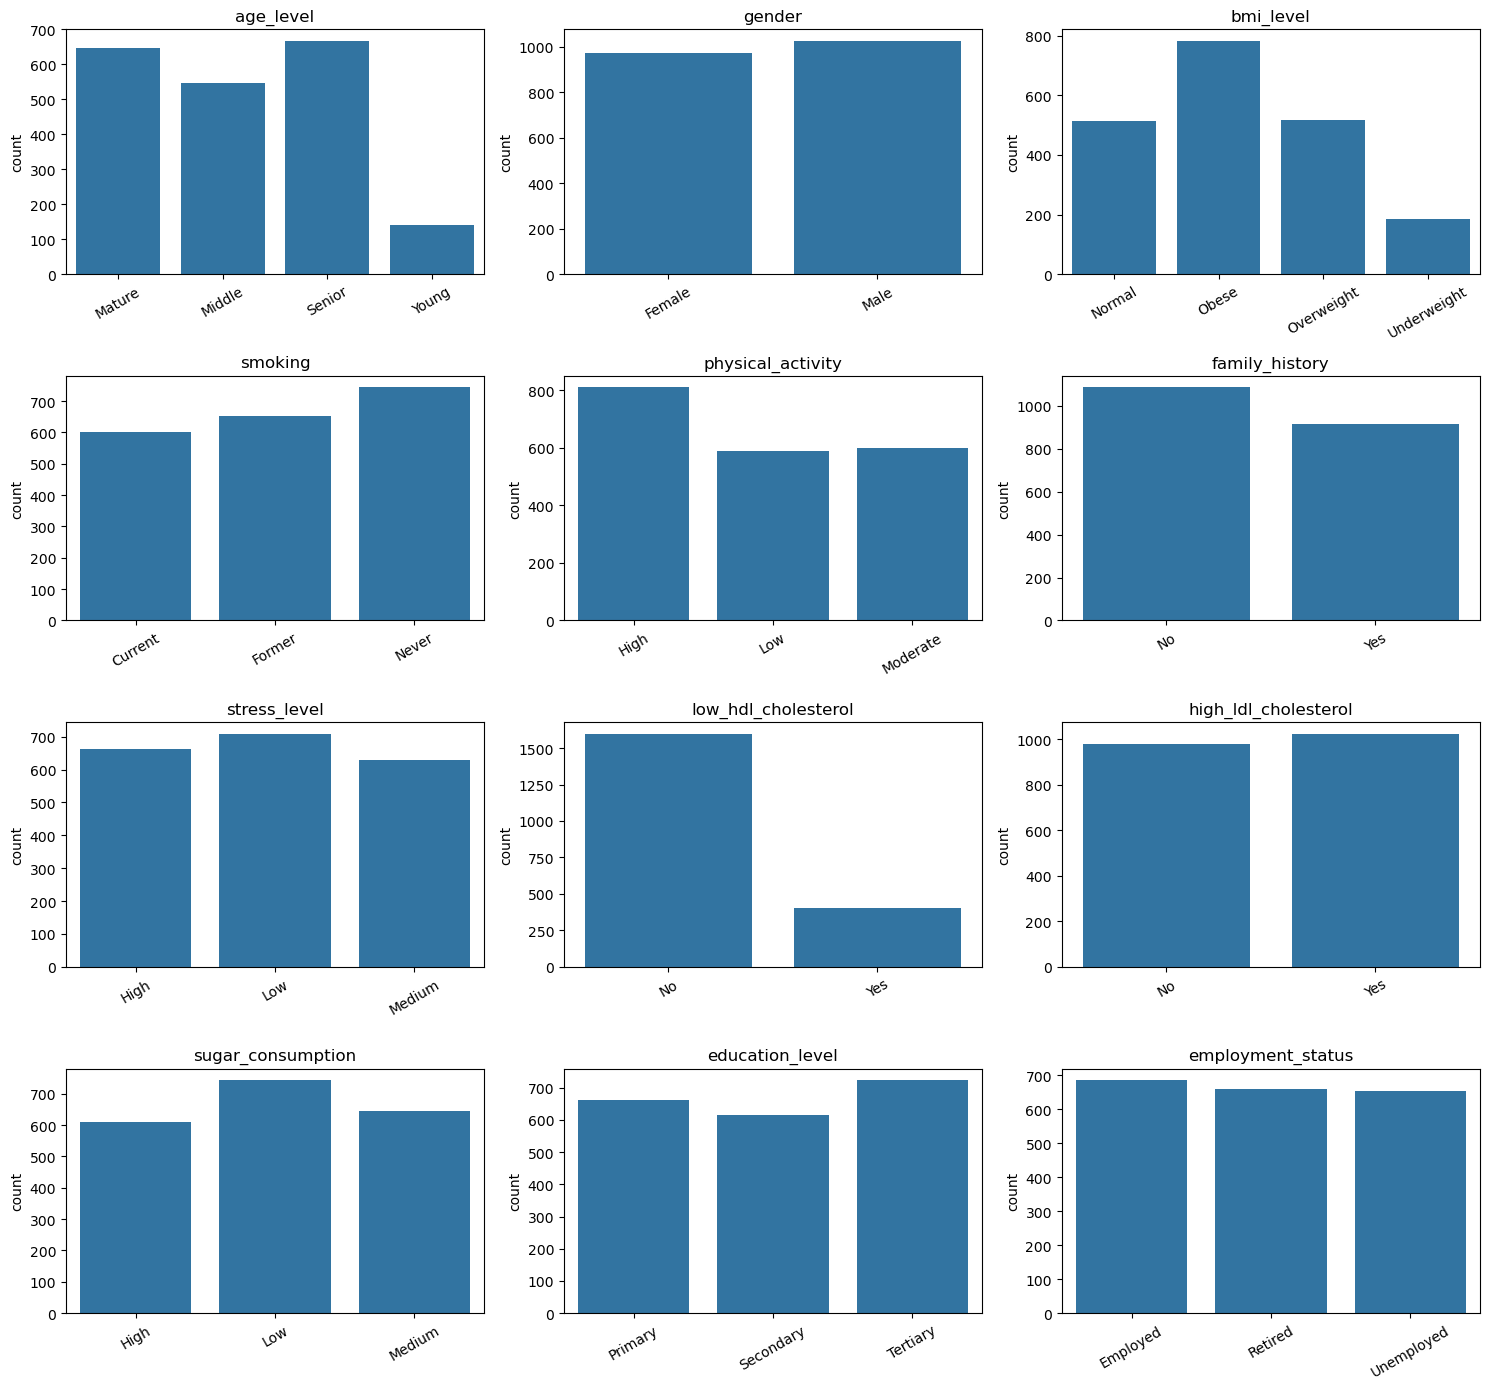

In [13]:
fig, axes = plt.subplots(4, 3, figsize=(15, 14))
for ax, col in zip(axes.ravel(), cat_cols):
    sns.countplot(x=df[col], ax=ax, order=sorted(df[col].unique()))
    ax.set_title(col)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

**Interpretação: variáveis categóricas**

- A maioria das variáveis categóricas está bem equilibrada entre categorias (ex.: `gender`, `smoking`, `stress_level`, `education_level`, `employment_status`).
- `age_level` tem poucos doentes na categoria "Young" (140, cerca de 7%).
- `bmi_level` tem poucos doentes "Underweight" (186) e uma maioria "Obese" (783), o que é coerente com um estudo sobre doenças cardiometabólicas.
- `low_hdl_cholesterol` está desequilibrada: só 402 doentes (20%) têm "Yes".
- Nenhuma variável categórica é constante, e não há categorias com tão poucos casos que justifiquem ser agrupadas.

### 3.3 Análise bivariada

Nesta secção analisamos a relação entre pares de variáveis e entre as variáveis e os dois alvos (`target_regression` e `target_class`). O objetivo é identificar variáveis redundantes (muito correlacionadas entre si) e variáveis relevantes para prever cada alvo.

#### 3.3.1 Correlação entre variáveis numéricas

Excluímos as quatro variáveis já identificadas como constantes ou redundantes (`calcium_baseline`, `systolic_index`, `age_normalized`, `ldl_alternative`).

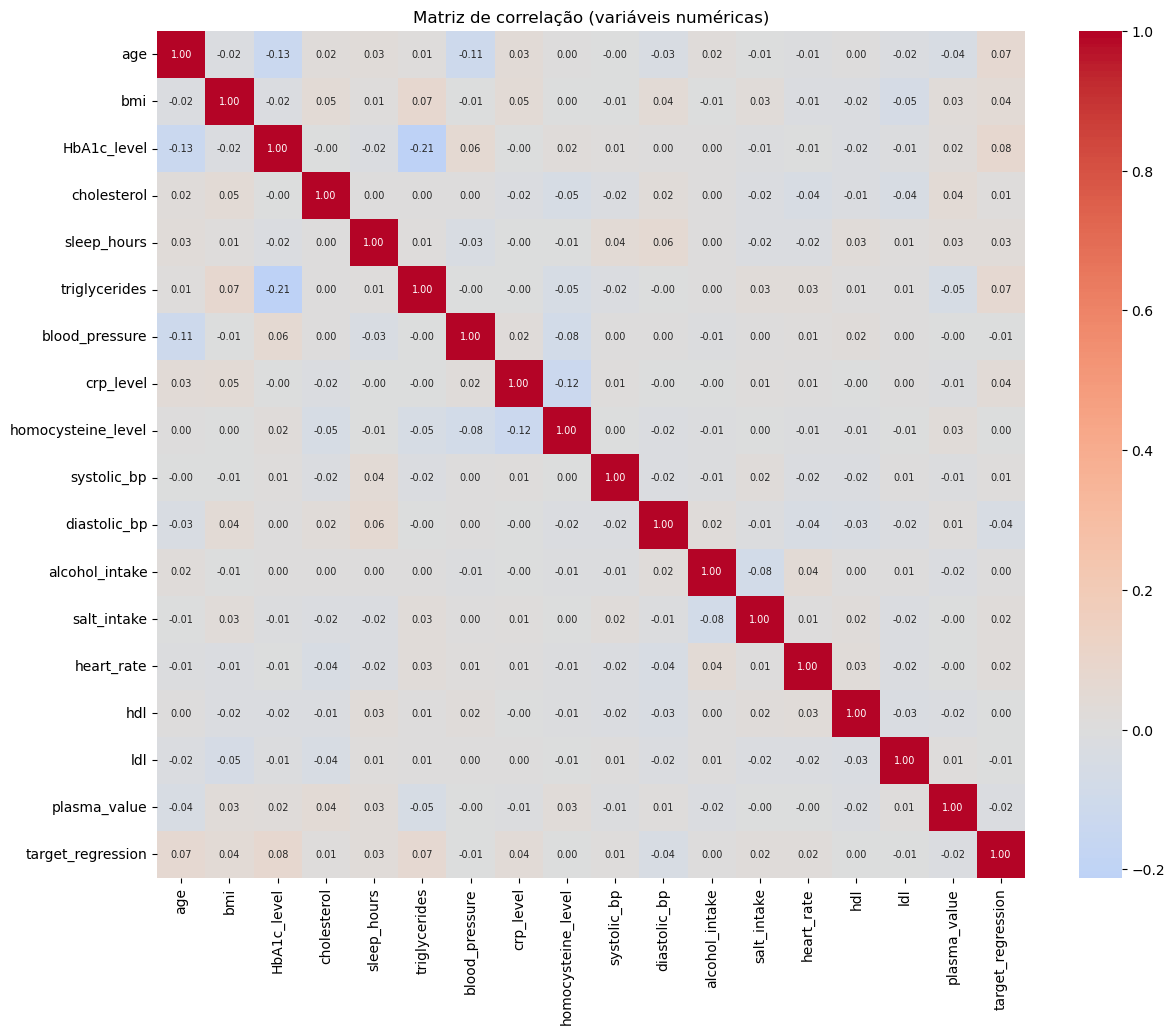

In [14]:
# Variáveis numéricas sem as constantes/redundantes
cols_uteis = [c for c in num_cols if c not in ['calcium_baseline', 'systolic_index',
                                               'age_normalized', 'ldl_alternative']]

plt.figure(figsize=(14, 11))
sns.heatmap(df[cols_uteis + ['target_regression']].corr(),
            cmap='coolwarm', center=0, annot=True, fmt='.2f', annot_kws={'size': 7})
plt.title('Matriz de correlação (variáveis numéricas)')
plt.show()

**Interpretação**

- As correlações entre as variáveis numéricas são todas **muito fracas** (|r| ≤ 0,21). As mais altas são negativas: `HbA1c_level` com `triglycerides` (−0,21), `HbA1c_level` com `age` (−0,13), `crp_level` com `homocysteine_level` (−0,12) e `blood_pressure` com `age` (−0,11).
- Não existe **multicolinearidade** entre as variáveis restantes, por isso, depois de removidas as 4 redundantes, não há mais variáveis a eliminar por este motivo.
- A correlação de todas as variáveis com `target_regression` também é fraca (|r| ≤ 0,08), o que sugere que um modelo linear terá dificuldade em prever este alvo (analisado em detalhe em 3.3.2).
- Parte desta falta de correlação pode dever-se aos valores imputados identificados na análise univariada: cerca de 35% dos doentes têm o mesmo valor em várias variáveis, o que "dilui" as relações lineares.

#### 3.3.2 Relação com o alvo de regressão

Ordenamos as variáveis numéricas pela correlação (em valor absoluto) com `target_regression`. Esta análise serve também de ponto de partida para escolher a variável da regressão linear simples.

In [15]:
corr_reg = df[cols_uteis].corrwith(df['target_regression'])
corr_reg = corr_reg.reindex(corr_reg.abs().sort_values(ascending=False).index)
corr_reg.round(3)

HbA1c_level           0.081
triglycerides         0.070
age                   0.065
diastolic_bp         -0.045
bmi                   0.044
crp_level             0.036
sleep_hours           0.032
salt_intake           0.019
heart_rate            0.019
plasma_value         -0.016
cholesterol           0.013
systolic_bp           0.012
ldl                  -0.008
blood_pressure       -0.008
alcohol_intake        0.002
homocysteine_level    0.000
hdl                   0.000
dtype: float64

**Interpretação**

Todas as variáveis têm uma correlação **muito fraca** com `target_regression`. A mais alta é a de `HbA1c_level` (r = 0,081), seguida de `triglycerides` (0,070) e `age` (0,065). Como R² = r² numa regressão linear simples, mesmo a melhor variável explicaria apenas cerca de 0,7% da variância do alvo. Espera-se, por isso, um desempenho fraco nos modelos de regressão linear, e a regressão múltipla deverá melhorar pouco em relação à simples. Várias variáveis têm correlação praticamente nula (`hdl`, `homocysteine_level`, `alcohol_intake`).

#### 3.3.3 Relação com o alvo de classificação

Comparamos a distribuição de cada variável numérica entre as três classes (DI, HT, HT_HY), através de boxplots e da média e desvio-padrão por classe.

In [16]:
df.groupby('target_class')[cols_uteis + ['target_regression']].agg(['mean', 'std']).round(2).T

target_class                 DI      HT   HT_HY
age                mean   54.17   63.98   60.64
                   std    20.50   15.17   16.77
bmi                mean   28.07   27.73   29.02
                   std     7.32    4.88    6.15
HbA1c_level        mean    6.93    5.41    5.40
                   std     0.51    0.84    0.77
cholesterol        mean  223.21  222.83  225.63
                   std    38.13   18.62   29.69
sleep_hours        mean    6.92    7.02    6.86
                   std     1.59    0.86    1.09
triglycerides      mean  164.30  219.76  229.99
                   std    66.22   61.95   76.86
blood_pressure     mean  150.39  149.00  149.42
                   std     5.15    6.56   11.67
crp_level          mean    7.37    7.58    7.25
                   std     1.24    1.85    2.76
homocysteine_level mean   12.34   12.41   12.52
                   std     1.22    2.07    2.93
systolic_bp        mean  134.94  134.51  134.50
                   std    22.72    0.91    0.87
diastolic_bp       mean   89.28   89.52   89.47
                   std    15.19    0.38    0.36
alcohol_intake     mean   14.86   15.00   14.95
                   std     7.67    0.28    0.28
salt_intake        mean    8.41    8.50    8.48
                   std     3.30    0.12    0.12
heart_rate         mean   74.03   74.30   74.43
                   std    12.65    0.51    0.49
hdl                mean   64.45   64.56   64.61
                   std    17.89    0.52    0.47
ldl                mean  128.12  129.33  129.44
                   std    31.18    1.48    1.38
plasma_value       mean    1.25    1.25    1.25
                   std     0.15    0.14    0.14
target_regression  mean  143.52  129.63  127.62
                   std    47.05   31.54   31.51

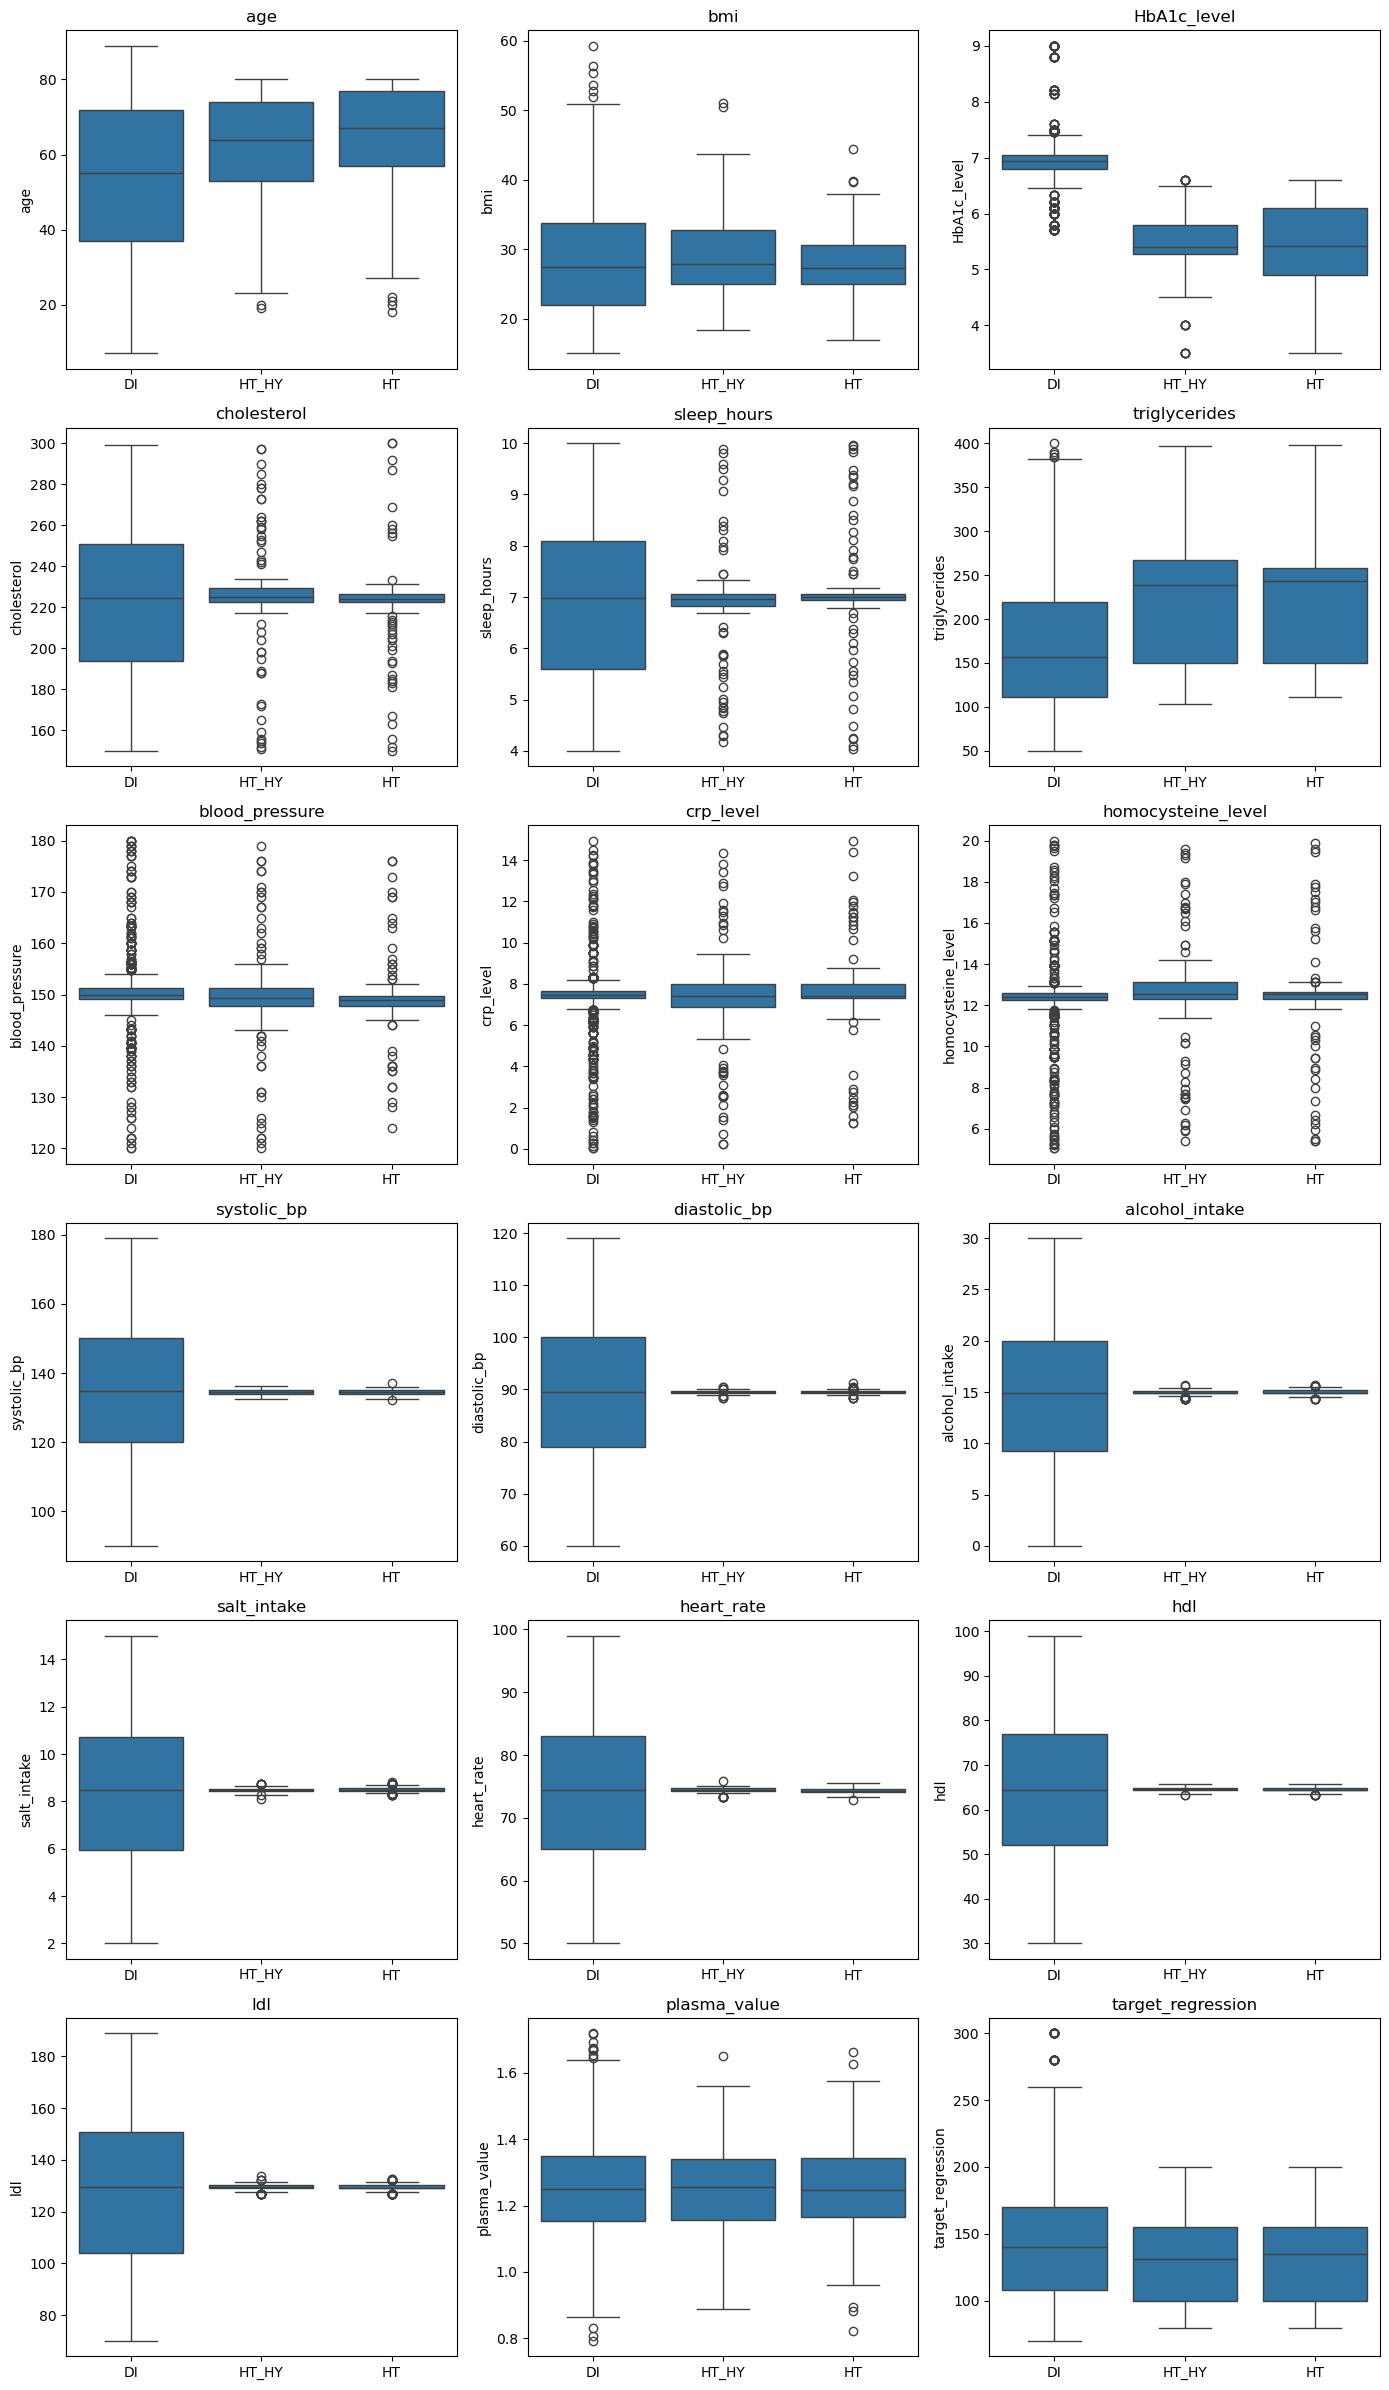

In [17]:
fig, axes = plt.subplots(6, 3, figsize=(14, 24))
for ax, col in zip(axes.ravel(), cols_uteis + ['target_regression']):
    sns.boxplot(x='target_class', y=col, data=df, ax=ax)
    ax.set_title(col)
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

**Interpretação**

**Variáveis que distinguem as classes:**
- `HbA1c_level` é a variável mais discriminante: os doentes DI têm valores muito mais altos (média 6,93) do que HT e HT_HY (≈ 5,4), com pouca sobreposição entre as caixas. Isto faz sentido clinicamente, já que a HbA1c é o marcador usado no diagnóstico da diabetes.
- `triglycerides` é mais baixa em DI (164) do que em HT (220) e HT_HY (230).
- `age`: os doentes DI são em média mais novos (54 anos) do que os HT (64) e HT_HY (61).

**Variáveis com valores imputados por classe:**
- Em `systolic_bp`, `diastolic_bp`, `alcohol_intake`, `salt_intake`, `heart_rate`, `hdl` e `ldl`, as classes HT e HT_HY têm desvio-padrão quase nulo (ex.: `systolic_bp`: 22,72 em DI vs 0,91 em HT). Ou seja, **para estas duas classes, praticamente todos os valores destas variáveis foram imputados com a média**. `cholesterol` e `sleep_hours` mostram o mesmo padrão, mas só em parte (caixa muito estreita, com alguns valores reais a aparecer como outliers).
- Isto significa que estas variáveis não trazem informação clínica sobre HT e HT_HY. No entanto, um classificador pode aprender que "valor igual à média" indica HT/HT_HY, o que é um **artefacto da recolha dos dados** e não um padrão real. Este aspeto será tido em conta na interpretação dos resultados da classificação.

**Variáveis sem diferenças entre classes:**
- `bmi`, `blood_pressure`, `crp_level`, `homocysteine_level` e `plasma_value` têm distribuições muito semelhantes nas três classes. Em particular, `plasma_value` tem a mesma média e desvio-padrão em todas as classes (1,25 ± 0,14) e correlação quase nula com `target_regression` (−0,016). É uma variável **pouco informativa**, mas mantemo-la para verificar na secção de seleção de variáveis se o Lasso a elimina.

**HT vs HT_HY:**
- As classes HT e HT_HY são praticamente iguais em todas as variáveis numéricas. As únicas diferenças, pequenas, são em `triglycerides` e `age`. Prevê-se que a maior dificuldade dos classificadores seja separar estas duas classes.

**Alvo de regressão:**
- `target_regression` é em média mais alta e mais dispersa em DI (143,5 ± 47,1) do que em HT (129,6) e HT_HY (127,6), com alguns valores extremos (até 300) apenas na classe DI.

#### 3.3.4 Variáveis categóricas vs. classe

Para cada variável categórica, calculamos a proporção de cada categoria dentro de cada classe. Se as proporções forem muito diferentes entre classes, a variável ajuda a distingui-las.

In [18]:
for col in cat_cols:
    print(f"--- {col} ---")
    print(pd.crosstab(df[col], df['target_class'], normalize='columns').round(2))
    print()

--- age_level ---
target_class    DI    HT  HT_HY
age_level                      
Mature        0.31  0.39   0.41
Middle        0.30  0.10   0.16
Senior        0.31  0.49   0.40
Young         0.08  0.02   0.04

--- gender ---
target_class   DI    HT  HT_HY
gender                        
Female        0.5  0.37   0.41
Male          0.5  0.63   0.59

--- bmi_level ---
target_class    DI    HT  HT_HY
bmi_level                      
Normal        0.26  0.24   0.23
Obese         0.41  0.27   0.37
Overweight    0.23  0.47   0.38
Underweight   0.11  0.02   0.02

--- smoking ---
target_class    DI    HT  HT_HY
smoking                        
Current       0.31  0.21   0.30
Former        0.33  0.37   0.25
Never         0.36  0.42   0.45

--- physical_activity ---
target_class         DI    HT  HT_HY
physical_activity                   
High               0.40  0.49   0.36
Low                0.29  0.30   0.33
Moderate           0.31  0.21   0.31

--- family_history ---
target_class      DI    HT

**Interpretação**

**Variáveis com diferenças entre DI e as classes de hipertensão (HT, HT_HY):**
- `gender`: em DI há tantos homens como mulheres (50/50), mas em HT e HT_HY predominam os homens (63% e 59%).
- `age_level`: as classes HT e HT_HY têm mais doentes "Senior" e "Mature" e muito menos "Middle" (10–16% vs 30% em DI), o que confirma a diferença de idades vista em `age`.
- `bmi_level`: DI tem mais doentes "Underweight" (11% vs 2%) e "Obese" (41%), enquanto HT tem muitos "Overweight" (47% vs 23% em DI). Esta diferença não aparecia na média de `bmi`, o que mostra que `bmi_level` capta informação que a variável contínua não mostra.
- `low_hdl_cholesterol`: a proporção de "Yes" é quase o dobro em HT (30%) e HT_HY (35%) face a DI (18%). Isto é relevante porque a variável numérica `hdl` foi imputada nestas classes, mas este indicador **mantém informação real**.
- `sugar_consumption`: metade dos doentes HT e HT_HY tem consumo "Low" (50% vs 35% em DI).
- `family_history`, `education_level` e `employment_status` mostram diferenças moderadas (ex.: escolaridade "Primary" em 35% dos DI vs ≈ 21% em HT/HT_HY).

**Variáveis sem diferenças relevantes:**
- `high_ldl_cholesterol` e `stress_level` têm proporções muito semelhantes nas três classes, sendo pouco informativas para a classificação.

**HT vs HT_HY:**
- Ao contrário das numéricas, algumas categóricas mostram diferenças entre HT e HT_HY: `smoking` ("Current" 21% vs 30%; "Former" 37% vs 25%), `physical_activity` ("High" 49% vs 36%) e `bmi_level` ("Overweight" 47% vs 38%; "Obese" 27% vs 37%). Estas variáveis podem ajudar a separar as duas classes mais difíceis.
- Como HT (183) e HT_HY (103) têm poucos doentes, estas proporções são menos estáveis do que as de DI e devem ser interpretadas com cautela.

### 3.4 Resumo da EDA e preparação dos dados

**Variáveis removidas:**

| Variável | Motivo |
|---|---|
| `calcium_baseline` | Constante (valor único 9,42) |
| `systolic_index` | Cópia exata de `systolic_bp` |
| `age_normalized` | Transformação linear de `age` (r = 1) |
| `ldl_alternative` | Permutação aleatória dos valores de `ldl` (r ≈ −0,02), ou seja, ruído |

**Variáveis mantidas, mas a ter em atenção:**
- `age_level` e `bmi_level` são derivadas de `age` e `bmi`, mas mantêm-se porque `bmi_level` mostrou diferenças entre classes que a variável contínua não mostra.
- `plasma_value` e `high_ldl_cholesterol` parecem pouco informativas; a seleção de variáveis (secção 6) vai confirmar se devem ser eliminadas.
- `systolic_bp`, `diastolic_bp`, `alcohol_intake`, `salt_intake`, `heart_rate`, `hdl` e `ldl` estão imputadas com a média para quase todos os doentes HT e HT_HY, o que pode criar um padrão artificial na classificação.

**Principais conclusões:**
- Dataset muito desbalanceado (DI 85,7%, HT 9,2%, HT_HY 5,2%), pelo que serão usadas métricas adequadas (F1-macro, recall por classe).
- `HbA1c_level`, `triglycerides` e `age` são as variáveis numéricas que mais distinguem as classes; HT e HT_HY são muito semelhantes entre si.
- Todas as variáveis têm correlação fraca com `target_regression` (|r| ≤ 0,08), pelo que se espera um R² baixo na regressão linear.
- Não foram removidos outliers, porque a maioria resulta do IQR estreito causado pela imputação.

In [19]:
df_clean = df.drop(columns=['calcium_baseline', 'systolic_index',
                            'age_normalized', 'ldl_alternative'])

# Atualizar as listas de variáveis
num_cols_clean = [c for c in num_cols if c in df_clean.columns]
print(df_clean.shape)
print(f"Numéricas ({len(num_cols_clean)}): {num_cols_clean}")

(2000, 31)
Numéricas (17): ['age', 'bmi', 'HbA1c_level', 'cholesterol', 'sleep_hours', 'triglycerides', 'blood_pressure', 'crp_level', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'plasma_value']


## 4. Regressão

O objetivo é prever `target_regression` (variável contínua) a partir das restantes variáveis. Construímos dois modelos:

1. **Regressão linear simples**: usa apenas uma variável. Testamos todas as variáveis numéricas e escolhemos a melhor.
2. **Regressão linear múltipla**: usa várias variáveis. Testamos diferentes combinações e escolhemos o melhor grupo.

Os modelos são avaliados com o método **holdout**: 80% dos dados para treino e 20% para teste. Usamos três métricas:
- **R²**: proporção da variância do alvo explicada pelo modelo (1 = perfeito; 0 = igual a prever sempre a média; negativo = pior do que a média);
- **MAE** (erro absoluto médio): erro médio, nas mesmas unidades do alvo;
- **RMSE** (raiz do erro quadrático médio): semelhante ao MAE, mas penaliza mais os erros grandes.

`target_class` não é usada como variável preditora, porque é a outra variável alvo do problema.

### 4.1 Preparação dos dados

Dividimos o `df_clean` em treino (80%) e teste (20%). A mesma divisão é usada em todos os modelos de regressão, para que a comparação seja justa.

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Variável alvo e preditoras (sem os dois alvos)
y = df_clean['target_regression']
X = df_clean.drop(columns=['target_regression', 'target_class'])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)

print("Treino:", X_train.shape, " Teste:", X_test.shape)

# Função auxiliar para calcular as 3 métricas
def avaliar(y_real, y_prev):
    return {
        'R2':   r2_score(y_real, y_prev),
        'MAE':  mean_absolute_error(y_real, y_prev),
        'RMSE': np.sqrt(mean_squared_error(y_real, y_prev))
    }

Treino: (1600, 29)  Teste: (400, 29)


### 4.2 Regressão linear simples

Treinamos um modelo para cada variável numérica (uma de cada vez) e avaliamos no conjunto de teste. Mostramos também o R² no treino, para verificar se há sobreajuste (*overfitting*): um R² de treino muito superior ao de teste indica que o modelo não generaliza.

In [21]:
resultados_simples = []

for col in num_cols_clean:
    modelo = LinearRegression()
    modelo.fit(X_train[[col]], y_train)

    metricas = avaliar(y_test, modelo.predict(X_test[[col]]))
    metricas['R2_treino'] = r2_score(y_train, modelo.predict(X_train[[col]]))
    metricas['variavel'] = col
    resultados_simples.append(metricas)

res_simples = (pd.DataFrame(resultados_simples)
               .set_index('variavel')
               .sort_values('R2', ascending=False)
               [['R2_treino', 'R2', 'MAE', 'RMSE']])
res_simples.round(4)

,R2_treino,R2,MAE,RMSE
variavel,,,,
triglycerides,0.0041,0.0014,33.5815,44.3351
HbA1c_level,0.0069,-0.0017,33.6805,44.4055
diastolic_bp,0.0013,-0.0020,33.3845,44.4115
sleep_hours,0.0004,-0.0038,33.4292,44.4505
bmi,0.0022,-0.0062,33.5269,44.5043
crp_level,0.0015,-0.0062,33.5798,44.5051
blood_pressure,0.0000,-0.0066,33.5245,44.5120
systolic_bp,0.0000,-0.0066,33.5278,44.5121
cholesterol,0.0000,-0.0068,33.5266,44.5166


Os valores de R² são todos próximos de 0 e as diferenças entre variáveis são muito pequenas. Por isso, a ordem obtida pode depender da divisão treino/teste. Para escolher a variável de forma mais robusta, e sem usar o conjunto de teste para tomar decisões, aplicamos **validação cruzada com 5 folds no conjunto de treino** e escolhemos a variável com maior R² médio.

In [22]:
from sklearn.model_selection import cross_val_score, KFold

kf = KFold(n_splits=5, shuffle=True, random_state=SEED)

cv_simples = {}
for col in num_cols_clean:
    scores = cross_val_score(LinearRegression(), X_train[[col]], y_train, cv=kf, scoring='r2')
    cv_simples[col] = {'R2_CV_media': scores.mean(), 'R2_CV_desvio': scores.std()}

res_cv_simples = pd.DataFrame(cv_simples).T.sort_values('R2_CV_media', ascending=False)
res_cv_simples.round(4)

,R2_CV_media,R2_CV_desvio
age,0.0039,0.0067
HbA1c_level,0.0039,0.0071
triglycerides,0.0004,0.0066
bmi,-0.0009,0.0063
crp_level,-0.0012,0.0019
heart_rate,-0.0020,0.0032
homocysteine_level,-0.0023,0.0019
salt_intake,-0.0023,0.0024
diastolic_bp,-0.0025,0.0059
systolic_bp,-0.0025,0.0016


Melhor variável (CV): age
Equação: y = 131.38 + 0.1955 × age
Métricas no teste: {'R2': -0.018, 'MAE': 33.7895, 'RMSE': 44.7651}


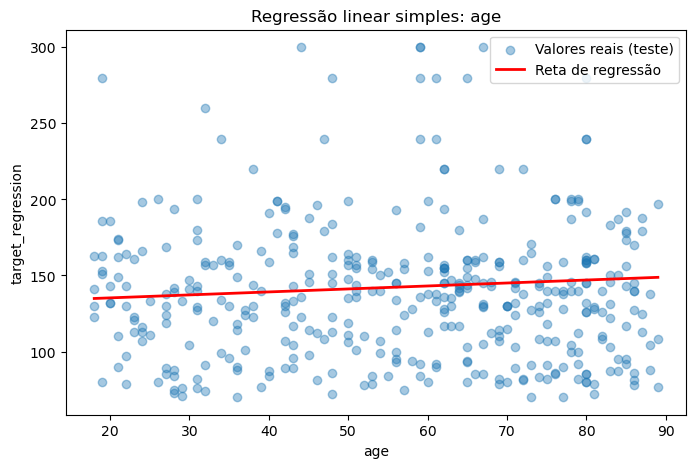

In [23]:
melhor_var = res_cv_simples.index[0]
print("Melhor variável (CV):", melhor_var)

modelo_simples = LinearRegression().fit(X_train[[melhor_var]], y_train)
y_prev_simples = modelo_simples.predict(X_test[[melhor_var]])

print(f"Equação: y = {modelo_simples.intercept_:.2f} + {modelo_simples.coef_[0]:.4f} × {melhor_var}")
print("Métricas no teste:", {k: round(v, 4) for k, v in avaliar(y_test, y_prev_simples).items()})

# Gráfico: pontos reais + reta do modelo
plt.figure(figsize=(8, 5))
plt.scatter(X_test[melhor_var], y_test, alpha=0.4, label='Valores reais (teste)')
ordem = X_test[melhor_var].sort_values()
plt.plot(ordem, modelo_simples.predict(ordem.to_frame()), color='red', linewidth=2, label='Reta de regressão')
plt.xlabel(melhor_var)
plt.ylabel('target_regression')
plt.title(f'Regressão linear simples: {melhor_var}')
plt.legend()
plt.show()

**Interpretação: regressão linear simples**

- Nenhuma variável consegue, sozinha, explicar `target_regression`: os R² de teste estão todos entre −0,018 e 0,001, e o MAE (≈ 33,5) e o RMSE (≈ 44,5) são praticamente iguais para todas as variáveis. Como o desvio-padrão do alvo é 45,4, o RMSE obtido é quase igual ao erro de prever sempre a média.
- Na validação cruzada, `age` e `HbA1c_level` obtiveram o mesmo R² médio (0,0039), mas com um desvio-padrão superior à média (≈ 0,007). Ou seja, o R² muda de sinal consoante os dados usados, e **nenhuma variável é significativamente melhor do que as outras**.
- Seguindo o critério definido (escolha por CV no treino), a variável selecionada foi `age`, com o modelo **target_regression = 131,38 + 0,1955 × age**. No conjunto de teste, este modelo obteve R² = −0,018, MAE = 33,79 e RMSE = 44,77, ficando em último lugar entre as 17 variáveis. Isto confirma que a ordem das variáveis é instável e resulta sobretudo de ruído.
- O gráfico mostra uma reta quase horizontal: passar de 20 para 90 anos aumenta a previsão em apenas ≈ 14 unidades, muito pouco face à variabilidade do alvo.
- Estes resultados estão de acordo com a EDA, onde todas as correlações com o alvo eram inferiores a 0,08 em valor absoluto.

### 4.3 Regressão linear múltipla

Testamos vários conjuntos de variáveis:

| Conjunto | Variáveis |
|---|---|
| Top 3 | As 3 melhores da regressão simples (pela CV) |
| Top 5 | As 5 melhores da regressão simples (pela CV) |
| Biomarcadores | Medições clínicas e laboratoriais (HbA1c, lípidos, pressão arterial, CRP, homocisteína, frequência cardíaca) |
| Todas numéricas | As 17 variáveis numéricas |
| Todas | Numéricas + categóricas (codificadas com *one-hot encoding*) |
| Seleção *forward* | Conjunto escolhido automaticamente: começa sem variáveis e vai adicionando a que mais melhora o R² (CV), parando quando a melhoria é inferior a 0,001 |

As variáveis categóricas são convertidas em colunas 0/1 (*one-hot encoding*), eliminando uma categoria de cada variável (`drop_first=True`) para evitar colinearidade perfeita. Tal como na regressão simples, o conjunto é escolhido pelo R² médio em validação cruzada (5 folds) no treino, e o teste serve apenas para a avaliação final.

In [24]:
from sklearn.feature_selection import SequentialFeatureSelector

# One-hot encoding das categóricas (mesma divisão treino/teste)
X_dum = pd.get_dummies(X, drop_first=True, dtype=int)
Xd_train = X_dum.loc[X_train.index]
Xd_test  = X_dum.loc[X_test.index]

# Seleção forward automática
sfs = SequentialFeatureSelector(LinearRegression(), n_features_to_select='auto', tol=0.001,
                                direction='forward', scoring='r2', cv=kf)
sfs.fit(Xd_train, y_train)
vars_forward = list(Xd_train.columns[sfs.get_support()])
print("Variáveis escolhidas pela seleção forward:", vars_forward)

# Conjuntos a testar
ranking = list(res_cv_simples.index)
conjuntos = {
    'Top 3':           ranking[:3],
    'Top 5':           ranking[:5],
    'Biomarcadores':   ['HbA1c_level', 'cholesterol', 'triglycerides', 'hdl', 'ldl',
                        'crp_level', 'homocysteine_level', 'blood_pressure',
                        'systolic_bp', 'diastolic_bp', 'heart_rate'],
    'Todas numéricas': num_cols_clean,
    'Todas':           list(X_dum.columns),
    'Seleção forward': vars_forward,
}

resultados_mult = []
for nome, cols in conjuntos.items():
    cv = cross_val_score(LinearRegression(), Xd_train[cols], y_train, cv=kf, scoring='r2')
    modelo = LinearRegression().fit(Xd_train[cols], y_train)
    met = avaliar(y_test, modelo.predict(Xd_test[cols]))
    met.update({'conjunto': nome, 'n_vars': len(cols),
                'R2_treino': r2_score(y_train, modelo.predict(Xd_train[cols])),
                'R2_CV_media': cv.mean(), 'R2_CV_desvio': cv.std()})
    resultados_mult.append(met)

res_mult = (pd.DataFrame(resultados_mult).set_index('conjunto')
            [['n_vars', 'R2_treino', 'R2_CV_media', 'R2_CV_desvio', 'R2', 'MAE', 'RMSE']]
            .sort_values('R2_CV_media', ascending=False))
res_mult.round(4)

Variáveis escolhidas pela seleção forward: ['age', 'HbA1c_level', 'triglycerides', 'crp_level', 'bmi_level_Overweight', 'family_history_Yes', 'sugar_consumption_Low', 'education_level_Secondary']


,n_vars,R2_treino,R2_CV_media,R2_CV_desvio,R2,MAE,RMSE
conjunto,,,,,,,
Seleção forward,8,0.0384,0.0280,0.0080,0.0269,33.9802,43.7663
Top 5,5,0.0269,0.0203,0.0057,-0.0023,34.1449,44.4174
Top 3,3,0.0237,0.0184,0.0081,-0.0023,33.9933,44.4189
Todas,39,0.0662,0.0182,0.0170,0.0594,33.4450,43.0293
Todas numéricas,17,0.0309,0.0108,0.0116,-0.0056,34.0587,44.4910
Biomarcadores,11,0.0186,0.0044,0.0135,0.0059,33.8244,44.2363


**Interpretação: regressão linear múltipla**

- O melhor conjunto, pelo critério definido (R² médio em CV), é o obtido pela **seleção forward**, com 8 variáveis: `age`, `HbA1c_level`, `triglycerides`, `crp_level`, `bmi_level_Overweight`, `family_history_Yes`, `sugar_consumption_Low` e `education_level_Secondary`. Obteve R² CV = 0,028 (± 0,008) e R² de teste = 0,027, os valores mais consistentes entre todos os conjuntos.
- Metade das variáveis selecionadas são categóricas, e são precisamente as que, na EDA, mostraram diferenças entre DI e as classes de hipertensão. Como `target_regression` também é mais elevada em DI, estas variáveis parecem atuar como **indicadores indiretos do diagnóstico**, que por sua vez está associado ao alvo.
- O conjunto com **todas as variáveis** (39) mostra **sobreajuste**: o R² cai de 0,066 no treino para 0,018 em CV. Apesar de ter o maior R² de teste (0,059), o desvio-padrão elevado na CV (0,017) indica que este resultado depende da divisão treino/teste e não é fiável.
- O conjunto **Biomarcadores** foi o pior (R² CV = 0,004), o que mostra que as medições clínicas, sozinhas, quase não explicam o alvo. Isto pode dever-se, em parte, aos valores imputados.
- Limitação: como a seleção forward usou a mesma validação cruzada para escolher as variáveis, o seu R² CV é ligeiramente otimista. O resultado no conjunto de teste, que não foi usado na seleção, confirma no entanto um valor semelhante.

### 4.4 Comparação e discussão

Comparamos o modelo simples (`age`) com o múltiplo (seleção forward) no conjunto de teste. Como referência, incluímos um **modelo de base** (*baseline*) que prevê sempre a média do alvo no treino: um modelo útil tem de ser melhor do que este.

,R2,MAE,RMSE
Baseline (média),-0.0067,33.5260,44.5156
Simples (age),-0.0180,33.7895,44.7651
Múltipla (seleção forward),0.0269,33.9802,43.7663



Coeficientes do modelo múltiplo:
HbA1c_level                  7.240
sugar_consumption_Low        6.644
bmi_level_Overweight         6.026
education_level_Secondary   -5.827
family_history_Yes          -3.982
crp_level                    1.062
age                          0.193
triglycerides                0.051
dtype: float64


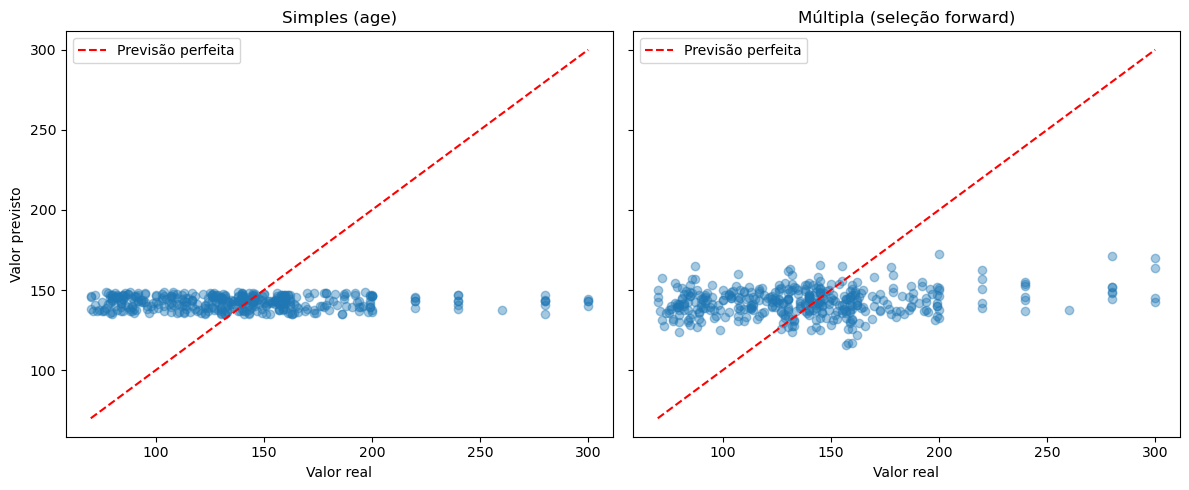

In [25]:
from sklearn.dummy import DummyRegressor

# Baseline: prevê sempre a média
baseline = DummyRegressor(strategy='mean').fit(X_train, y_train)
y_prev_base = baseline.predict(X_test)

# Modelo múltiplo final
modelo_mult = LinearRegression().fit(Xd_train[vars_forward], y_train)
y_prev_mult = modelo_mult.predict(Xd_test[vars_forward])

comparacao = pd.DataFrame({
    'Baseline (média)':               avaliar(y_test, y_prev_base),
    f'Simples ({melhor_var})':        avaliar(y_test, y_prev_simples),
    'Múltipla (seleção forward)':     avaliar(y_test, y_prev_mult),
}).T
display(comparacao.round(4))

# Coeficientes do modelo múltiplo
coefs = pd.Series(modelo_mult.coef_, index=vars_forward).sort_values(key=abs, ascending=False)
print("\nCoeficientes do modelo múltiplo:")
print(coefs.round(3))

# Gráfico: valores reais vs previstos
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
for ax, prev, titulo in zip(axes, [y_prev_simples, y_prev_mult],
                            [f'Simples ({melhor_var})', 'Múltipla (seleção forward)']):
    ax.scatter(y_test, prev, alpha=0.4)
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', label='Previsão perfeita')
    ax.set_xlabel('Valor real')
    ax.set_title(titulo)
    ax.legend()
axes[0].set_ylabel('Valor previsto')
plt.tight_layout()
plt.show()

**Discussão**

| Modelo | R² | MAE | RMSE |
|---|---|---|---|
| Baseline (média) | −0,0067 | 33,53 | 44,52 |
| Simples (`age`) | −0,0180 | 33,79 | 44,77 |
| Múltipla (seleção forward, 8 variáveis) | **0,0269** | 33,98 | **43,77** |

- O **modelo simples** é pior do que o baseline nas três métricas: usar apenas a idade não traz qualquer vantagem em relação a prever sempre a média.
- O **modelo múltiplo** é o único com R² positivo e reduz o RMSE em cerca de 0,75 unidades (≈ 1,7%) face ao baseline. No entanto, o seu MAE é ligeiramente superior. Isto indica que o modelo reduz um pouco os erros grandes (que o RMSE penaliza mais), mas o erro médio mantém-se. A melhoria é, por isso, **marginal**: o modelo explica menos de 3% da variância do alvo.
- O gráfico de valores reais vs previstos mostra que ambos os modelos fazem previsões concentradas numa faixa estreita (≈ 115–175), enquanto os valores reais variam entre 70 e 300. Os modelos **subestimam sistematicamente os valores altos e sobrestimam os baixos**, um comportamento típico de quando as variáveis preditoras têm pouca relação com o alvo.
- Nos coeficientes, o efeito positivo de `HbA1c_level` (+7,24 por unidade) é coerente com a EDA: os doentes DI têm HbA1c mais elevada e também valores mais altos de `target_regression`. Outros coeficientes, como os de `sugar_consumption_Low` ou `education_level_Secondary`, não têm uma interpretação clínica clara. Dado o R² muito baixo, os coeficientes são instáveis e não devem ser interpretados como relações causais. Note-se ainda que os coeficientes não são diretamente comparáveis entre si, porque as variáveis não foram normalizadas e estão em escalas diferentes.

**Conclusão:** as variáveis disponíveis têm uma relação linear muito fraca com `target_regression`. A regressão múltipla é preferível à simples, mas nenhum dos modelos tem utilidade prática para prever este biomarcador. Possíveis causas são a elevada proporção de valores imputados (que reduz a variabilidade real das variáveis), a existência de relações não lineares que um modelo linear não capta, ou o alvo depender de fatores não presentes no dataset.

## 5. Classificação

O objetivo é prever `target_class` (DI, HT ou HT_HY) com dois métodos:

- **Regressão Logística (multinomial):** modela diretamente a probabilidade de cada classe através de uma função logística. Não assume nenhuma distribuição para as variáveis.
- **Análise Discriminante Linear (LDA):** assume que, dentro de cada classe, as variáveis seguem uma distribuição normal multivariada com a mesma matriz de covariância em todas as classes. Classifica cada doente na classe com maior probabilidade *a posteriori* (teorema de Bayes).

**Pré-processamento:**
- As variáveis categóricas são convertidas em colunas 0/1 (*one-hot encoding*, `drop_first=True`).
- As variáveis são **normalizadas** (média 0, desvio-padrão 1) para a Regressão Logística, porque estão em escalas muito diferentes. A normalização é feita dentro de um `Pipeline`, para ser calculada apenas com os dados de treino em cada divisão e evitar fuga de informação (*data leakage*).
- `target_regression` não é usada como preditora, porque é a outra variável alvo.

**Métricas:** como o dataset é muito desbalanceado (DI 85,7%), a *accuracy* é enganadora: um modelo que previsse sempre "DI" teria 85,7% de accuracy sem ter aprendido nada. Por isso usamos como métrica principal o **F1-macro**, que calcula o F1 de cada classe e faz a média sem ter em conta o tamanho de cada uma, dando o mesmo peso às classes minoritárias. Reportamos também a *balanced accuracy* (média do recall de cada classe) e a accuracy, para comparação.

**Divisões estratificadas:** em todos os métodos de reamostragem, as divisões são estratificadas, isto é, mantêm a proporção de cada classe em treino e teste. Sem isto, algumas divisões poderiam ficar com muito poucos (ou nenhuns) doentes HT_HY.

### 5.1 Preparação dos dados e modelos

In [26]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)

# Dados de classificação
nomes_modelos = ['Regressão Logística', 'LDA']
X_cls = pd.get_dummies(df_clean.drop(columns=['target_class', 'target_regression']),
                       drop_first=True, dtype=int)
y_cls = df_clean['target_class']
print("X:", X_cls.shape, " | Classes:", y_cls.value_counts().to_dict())

# As variáveis são **normalizadas** (média 0, desvio-padrão 1). 
# A média e o desvio-padrão são calculados apenas com os dados de treino de cada divisão e depois aplicados ao teste, para evitar fuga de informação (*data leakage*).
def treinar_e_prever(nome, X_treino, y_treino, X_teste):
    # Normaliza com a média e o desvio-padrão do TREINO e aplica o mesmo ao teste
    scaler = StandardScaler()
    X_treino_n = scaler.fit_transform(X_treino)
    X_teste_n = scaler.transform(X_teste)

    if nome == 'Regressão Logística':
        modelo = LogisticRegression(max_iter=2000, random_state=SEED)
    else:
        modelo = LinearDiscriminantAnalysis()

    modelo.fit(X_treino_n, y_treino)
    return modelo.predict(X_teste_n)

# Métricas
def metricas_cls(y_real, y_prev):
    return {
        'F1_macro':          f1_score(y_real, y_prev, average='macro'),
        'Balanced_accuracy': balanced_accuracy_score(y_real, y_prev),
        'Accuracy':          accuracy_score(y_real, y_prev),
    }

X: (2000, 39)  | Classes: {'DI': 1714, 'HT': 183, 'HT_HY': 103}


### 5.2 Holdout

Dividimos os dados em 80% treino e 20% teste (estratificado), treinamos cada modelo uma vez e avaliamos no teste.

Teste: {'DI': 343, 'HT': 36, 'HT_HY': 21} 

===== Regressão Logística =====
              precision    recall  f1-score   support

          DI      0.957     0.983     0.970       343
          HT      0.488     0.556     0.519        36
       HT_HY      0.000     0.000     0.000        21

    accuracy                          0.892       400
   macro avg      0.482     0.513     0.496       400
weighted avg      0.865     0.892     0.878       400

===== LDA =====
              precision    recall  f1-score   support

          DI      0.946     0.980     0.963       343
          HT      0.387     0.333     0.358        36
       HT_HY      0.143     0.095     0.114        21

    accuracy                          0.875       400
   macro avg      0.492     0.469     0.478       400
weighted avg      0.854     0.875     0.864       400



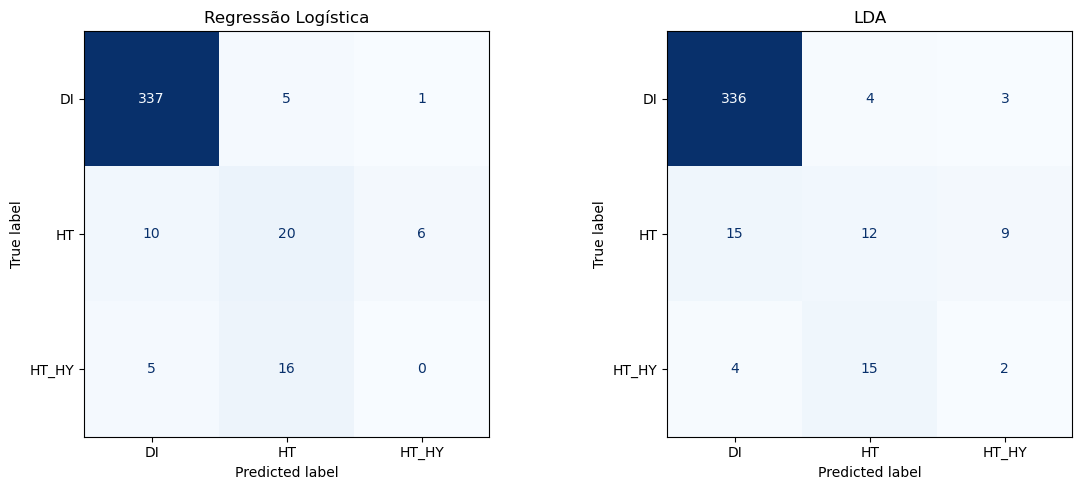

,F1_macro,Balanced_accuracy,Accuracy
Regressão Logística,0.4964,0.5127,0.8925
LDA,0.4784,0.4694,0.8750


In [27]:
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_cls, y_cls, test_size=0.2, stratify=y_cls, random_state=SEED)

print("Teste:", yc_test.value_counts().to_dict(), "\n")

res_holdout = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, nome in zip(axes, nomes_modelos):
    prev = treinar_e_prever(nome, Xc_train, yc_train, Xc_test)
    res_holdout[nome] = metricas_cls(yc_test, prev)

    print(f"===== {nome} =====")
    print(classification_report(yc_test, prev, digits=3))

    ConfusionMatrixDisplay.from_predictions(yc_test, prev, ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(nome)

plt.tight_layout()
plt.show()

res_holdout = pd.DataFrame(res_holdout).T
res_holdout.round(4)

**Interpretação: holdout**

- A **accuracy** é elevada (89,3% na Regressão Logística e 87,5% na LDA), mas é enganadora: um modelo que previsse sempre "DI" teria 85,8% neste conjunto de teste (343/400). O **F1-macro** (0,496 e 0,478) mostra que o desempenho nas classes minoritárias é fraco.
- A classe **DI** é bem identificada pelos dois modelos (recall ≈ 98%), o que é coerente com a EDA: `HbA1c_level` separa bem DI das restantes classes.
- A classe **HT_HY** é praticamente impossível de identificar: a Regressão Logística não acerta nenhum caso (16 dos 21 são classificados como HT) e a LDA acerta apenas 2. Como HT e HT_HY são muito semelhantes, os modelos tendem a escolher a classe com mais exemplos (HT).
- Há também doentes HT e HT_HY classificados como DI (15 na Regressão Logística e 19 na LDA), devido à sobreposição dos valores de HbA1c entre as classes.
- A **Regressão Logística** obteve melhores resultados do que a LDA em F1-macro e balanced accuracy. Uma explicação provável é a violação dos pressupostos da LDA: (1) a LDA assume que todas as classes têm a mesma matriz de covariância, mas, devido à imputação, várias variáveis têm variância muito diferente entre classes (ex.: desvio-padrão de `systolic_bp` = 22,7 em DI vs 0,9 em HT); (2) a LDA assume normalidade, o que não se verifica nas variáveis binárias do one-hot encoding. A Regressão Logística não depende destes pressupostos.
- Como o holdout usa apenas uma divisão (com só 21 casos HT_HY no teste), estes resultados podem variar bastante consoante a divisão. Nas secções seguintes usamos outros métodos de reamostragem para obter estimativas mais fiáveis.

### 5.3 Validação cruzada (k = 5 e k = 10)

Para estudar a variância das estimativas, recolhemos o F1-macro de cada avaliação individual (cada fold ou cada repetição) e calculamos a média e o desvio-padrão. Além do holdout simples, repetimos o holdout 30 vezes com divisões diferentes (estratificadas), para medir quanto o resultado do holdout varia de uma divisão para outra.

Na validação cruzada estratificada com *k* folds, os dados são divididos em *k* partes com a mesma proporção de classes; cada parte é usada uma vez como teste e as restantes como treino.

In [28]:
import warnings
from sklearn.exceptions import UndefinedMetricWarning
from sklearn.model_selection import StratifiedKFold, cross_validate
warnings.filterwarnings('ignore', category=UndefinedMetricWarning)

resultados_cls = []   # tabela final
dist_f1 = {}          # F1 de cada avaliação, para o gráfico da variância

def registar(metodo, nome, f1s, bals, accs):
    f1s, bals, accs = np.array(f1s), np.array(bals), np.array(accs)
    resultados_cls.append({
        'Método': metodo, 'Modelo': nome, 'n_avaliações': len(f1s),
        'F1_macro': f1s.mean(),  'F1_desvio': f1s.std() if len(f1s) > 1 else np.nan,
        'Bal_acc': bals.mean(),  'Bal_acc_desvio': bals.std() if len(bals) > 1 else np.nan,
        'Accuracy': accs.mean(), 'Acc_desvio': accs.std() if len(accs) > 1 else np.nan,
    })
    dist_f1[(metodo, nome)] = f1s

# 1) Holdout simples (já calculado)
for nome, r in res_holdout.iterrows():
    registar('Holdout', nome, [r['F1_macro']], [r['Balanced_accuracy']], [r['Accuracy']])

# 2) Holdout repetido 30 vezes
for nome in nomes_modelos:
    f1s, bals, accs = [], [], []
    for s in range(30):
        Xa, Xb, ya, yb = train_test_split(X_cls, y_cls, test_size=0.2, stratify=y_cls, random_state=s)
        prev = treinar_e_prever(nome, Xa, ya, Xb)
        m = metricas_cls(yb, prev)
        f1s.append(m['F1_macro']); bals.append(m['Balanced_accuracy']); accs.append(m['Accuracy'])
    registar('Holdout repetido (30x)', nome, f1s, bals, accs)

# 3) Validação cruzada estratificada k=5 e k=10
for k in [5, 10]:
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=SEED)
    for nome in nomes_modelos:
        f1s, bals, accs = [], [], []
        for idx_tr, idx_te in skf.split(X_cls, y_cls):
            prev = treinar_e_prever(nome, X_cls.iloc[idx_tr], y_cls.iloc[idx_tr], X_cls.iloc[idx_te])
            m = metricas_cls(y_cls.iloc[idx_te], prev)
            f1s.append(m['F1_macro']); bals.append(m['Balanced_accuracy']); accs.append(m['Accuracy'])
        registar(f'CV k={k}', nome, f1s, bals, accs)

pd.DataFrame(resultados_cls).round(4)

,Método,Modelo,n_avaliações,F1_macro,F1_desvio,Bal_acc,Bal_acc_desvio,Accuracy,Acc_desvio
0,Holdout,Regressão Logística,1,0.4964,NaN,0.5127,NaN,0.8925,NaN
1,Holdout,LDA,1,0.4784,NaN,0.4694,NaN,0.8750,NaN
2,Holdout repetido (30x),Regressão Logística,30,0.5576,0.0316,0.5620,0.0294,0.8996,0.0092
3,Holdout repetido (30x),LDA,30,0.5569,0.0338,0.5408,0.0307,0.8965,0.0073
4,CV k=5,Regressão Logística,5,0.5650,0.0470,0.5667,0.0437,0.9030,0.0109
5,CV k=5,LDA,5,0.5523,0.0524,0.5388,0.0412,0.8980,0.0111
6,CV k=10,Regressão Logística,10,0.5690,0.0434,0.5743,0.0329,0.9035,0.0074
7,CV k=10,LDA,10,0.5594,0.0597,0.5465,0.0474,0.9000,0.0143


**Interpretação: holdout repetido e validação cruzada**

- O F1-macro do holdout simples (0,496) ficou bastante abaixo da média do holdout repetido (0,558 ± 0,032), quase 2 desvios-padrão abaixo. A divisão usada no holdout simples foi, por acaso, desfavorável. Isto ilustra a principal limitação do holdout: **uma única divisão pode dar uma estimativa muito afastada do desempenho real**.
- A validação cruzada obteve valores ligeiramente superiores (F1-macro ≈ 0,57 na Regressão Logística), porque cada doente é usado uma vez como teste e, no caso de k=10, os modelos são treinados com 90% dos dados (vs 80% no holdout).
- O desvio-padrão do **F1-macro** (0,03–0,06) é muito superior ao da **accuracy** (0,007–0,014). O F1-macro depende fortemente do desempenho na classe HT_HY, que tem muito poucos casos em cada fold (≈ 10 com k=10), pelo que cada acerto ou erro nesta classe altera bastante o resultado.
- A **Regressão Logística** obteve um F1-macro superior ao da LDA na CV (k=5: 0,565 vs 0,552; k=10: 0,569 vs 0,559) e uma balanced accuracy superior em todos os métodos. A diferença é pequena e inferior ao desvio-padrão, mas é **consistente** entre métodos de reamostragem.
- Nota: o desvio-padrão desta tabela mede a variação entre folds (ou repetições) individuais. A variância da **estimativa final** de cada método (a média) é analisada na secção 5.6.

### 5.4 Leave-One-Out Cross Validation (LOOCV)

No LOOCV, cada doente é usado uma vez como teste e os restantes 1999 como treino, o que resulta em 2000 modelos por método. Como cada teste tem apenas um doente, não é possível calcular o F1-macro em cada iteração. Por isso, juntamos as 2000 previsões e calculamos as métricas uma única vez no final, pelo que não há desvio-padrão entre iterações.

In [29]:
import time
from sklearn.model_selection import LeaveOneOut

prev_loocv = {}
for nome in nomes_modelos:
    inicio = time.time()
    prev = []
    for idx_tr, idx_te in LeaveOneOut().split(X_cls):
        p = treinar_e_prever(nome, X_cls.iloc[idx_tr], y_cls.iloc[idx_tr], X_cls.iloc[idx_te])
        prev.append(p[0])
    prev = np.array(prev)
    prev_loocv[nome] = prev
    m = metricas_cls(y_cls, prev)
    registar('LOOCV', nome, [m['F1_macro']], [m['Balanced_accuracy']], [m['Accuracy']])
    print(f"{nome}: F1-macro = {m['F1_macro']:.4f}  ({time.time() - inicio:.0f} s)")

Regressão Logística: F1-macro = 0.5729  (40 s)
LDA: F1-macro = 0.5474  (24 s)


**Interpretação: LOOCV**

- O LOOCV obteve um F1-macro de 0,573 na Regressão Logística e 0,547 na LDA, valores muito próximos dos da CV com k=5 e k=10. Isto mostra que, com 2000 doentes, a CV com k=10 já dá uma estimativa praticamente igual à do LOOCV.
- O LOOCV é **determinístico**: não há aleatoriedade na divisão, por isso o resultado é sempre o mesmo. No entanto, os 2000 modelos são treinados com conjuntos de treino quase idênticos (diferem num único doente), pelo que as suas previsões estão muito correlacionadas. Segundo a teoria (James et al., *ISLR*), isto faz com que o LOOCV tenha baixo enviesamento, mas uma variância superior à da CV com k=5 ou k=10.
- O custo computacional é muito superior: a Regressão Logística demorou cerca de 50 s (2000 modelos), contra poucos segundos na CV com k=10 (10 modelos), sem ganho na qualidade da estimativa.

### 5.5 Bootstrap

Em cada iteração, sorteamos 2000 doentes **com reposição** (o mesmo doente pode sair várias vezes) para treino. Os doentes que não saíram (*out-of-bag*, cerca de 36,8% dos dados) são usados como teste. O sorteio é estratificado, para manter a proporção das classes. Repetimos o processo B = 200 vezes.

In [30]:
from sklearn.utils import resample

B = 200
idx_todos = np.arange(len(y_cls))

for nome in nomes_modelos:
    f1s, bals, accs = [], [], []
    inicio = time.time()
    for b in range(B):
        idx_treino = resample(idx_todos, replace=True, n_samples=len(idx_todos),
                              stratify=y_cls, random_state=b)
        idx_oob = np.setdiff1d(idx_todos, idx_treino)   # doentes que não saíram no sorteio

        prev = treinar_e_prever(nome, X_cls.iloc[idx_treino], y_cls.iloc[idx_treino], X_cls.iloc[idx_oob])
        m = metricas_cls(y_cls.iloc[idx_oob], prev)
        f1s.append(m['F1_macro']); bals.append(m['Balanced_accuracy']); accs.append(m['Accuracy'])

    registar(f'Bootstrap (B={B})', nome, f1s, bals, accs)
    print(f"{nome}: concluído ({time.time() - inicio:.0f} s)")

tabela_cls = pd.DataFrame(resultados_cls)
tabela_cls.round(4)

Regressão Logística: concluído (7 s)
LDA: concluído (5 s)


,Método,Modelo,n_avaliações,F1_macro,F1_desvio,Bal_acc,Bal_acc_desvio,Accuracy,Acc_desvio
0,Holdout,Regressão Logística,1,0.4964,NaN,0.5127,NaN,0.8925,NaN
1,Holdout,LDA,1,0.4784,NaN,0.4694,NaN,0.8750,NaN
2,Holdout repetido (30x),Regressão Logística,30,0.5576,0.0316,0.5620,0.0294,0.8996,0.0092
3,Holdout repetido (30x),LDA,30,0.5569,0.0338,0.5408,0.0307,0.8965,0.0073
4,CV k=5,Regressão Logística,5,0.5650,0.0470,0.5667,0.0437,0.9030,0.0109
5,CV k=5,LDA,5,0.5523,0.0524,0.5388,0.0412,0.8980,0.0111
6,CV k=10,Regressão Logística,10,0.5690,0.0434,0.5743,0.0329,0.9035,0.0074
7,CV k=10,LDA,10,0.5594,0.0597,0.5465,0.0474,0.9000,0.0143
8,LOOCV,Regressão Logística,1,0.5729,NaN,0.5736,NaN,0.9040,NaN
9,LOOCV,LDA,1,0.5474,NaN,0.5333,NaN,0.8965,NaN


**Interpretação: Bootstrap**

- O bootstrap obteve um F1-macro de 0,575 ± 0,026 na Regressão Logística e 0,565 ± 0,027 na LDA, valores coerentes com os restantes métodos.
- O desvio-padrão entre iterações é o mais baixo de todos os métodos, porque cada conjunto de teste *out-of-bag* tem cerca de 740 doentes (≈ 36,8%), mais do que no holdout (400) ou em cada fold da CV com k=10 (200). Conjuntos de teste maiores dão estimativas individuais mais estáveis, sobretudo para a classe HT_HY.
- Em teoria, o bootstrap tende a ser ligeiramente **pessimista**, porque cada modelo é treinado com apenas ≈ 63,2% de doentes distintos. Neste caso, esse efeito não é visível: a diferença para a CV está dentro da variabilidade observada.

**Resumo de todos os métodos (F1-macro, Regressão Logística):**

| Método | F1-macro | Desvio entre avaliações | Doentes no teste |
|---|---|---|---|
| Holdout | 0,496 | — | 400 |
| Holdout repetido (30×) | 0,558 | 0,032 | 400 |
| CV k=5 | 0,565 | 0,047 | 400 |
| CV k=10 | 0,569 | 0,043 | 200 |
| LOOCV | 0,573 | — | 1 |
| Bootstrap (B=200) | 0,575 | 0,026 | ≈ 740 |

## 5.6 Escolha do método e discussão da variância

### Método mais adequado

Comparando os dois métodos em todas as reamostragens (tabela abaixo), a Regressão Logística obteve F1-macro e balanced accuracy superiores às da LDA nos seis métodos.

| Método | F1-macro (Reg. Logística) | F1-macro (LDA) | Balanced acc. (Reg. Logística) | Balanced acc. (LDA) |
|---|---|---|---|---|
| Holdout | 0,496 | 0,478 | 0,513 | 0,469 |
| Holdout repetido (30×) | 0,558 | 0,557 | 0,562 | 0,541 |
| CV k=5 | 0,565 | 0,552 | 0,567 | 0,539 |
| CV k=10 | 0,569 | 0,559 | 0,574 | 0,547 |
| LOOCV | 0,573 | 0,547 | 0,574 | 0,533 |
| Bootstrap (B=200) | 0,575 | 0,565 | 0,570 | 0,547 |

A diferença no F1-macro é pequena (entre 0,001 e 0,026) quando comparada com o desvio-padrão entre folds (0,03 a 0,06), pelo que, só com estes números, não podemos afirmar que a Regressão Logística seja significativamente melhor. No entanto, a vantagem é **consistente**: aparece em todos os métodos e nas duas métricas, e é maior na balanced accuracy (0,02 a 0,04).

Consideramos a **Regressão Logística** o método mais adequado a este problema, pelas seguintes razões:

1. **Pressupostos da LDA não se verificam.** A LDA assume que, dentro de cada classe, as variáveis seguem uma distribuição normal e que todas as classes partilham a mesma matriz de covariância. Na EDA vimos que isto não acontece: várias variáveis (`systolic_bp`, `diastolic_bp`, `alcohol_intake`, `salt_intake`, `heart_rate`, `hdl` e `ldl`) têm um desvio-padrão muito elevado na classe DI (por exemplo, 22,7 no `systolic_bp`) e quase nulo em HT e HT_HY (0,9), porque os seus valores foram provavelmente imputados com a média. A Regressão Logística não assume nenhuma distribuição para as variáveis, pelo que não é afetada por esta violação.
2. **Variáveis binárias.** Depois do *one-hot encoding*, cerca de metade das variáveis toma apenas os valores 0 e 1, o que também contraria a hipótese de normalidade da LDA.
3. **Melhor desempenho nas classes minoritárias.** A balanced accuracy (média do recall de cada classe) é superior em todos os métodos. No holdout, por exemplo, o recall da classe HT foi de 0,56 na Regressão Logística contra 0,33 na LDA. A exceção é a classe HT_HY, onde nenhum dos modelos tem bom desempenho (recall de 0 na Regressão Logística e de 0,10 na LDA).

**Limitações.** Nenhum dos modelos consegue identificar bem a classe HT_HY, que é muito semelhante à HT em quase todas as variáveis e tem poucos doentes (103), pelo que o F1-macro máximo obtido é de apenas ≈ 0,57. Além disso, como as classes HT e HT_HY têm valores imputados com a média em várias variáveis, os modelos podem usar o facto de "o valor ser igual à média" como sinal de pertença a essas classes. Este é um artefato da recolha dos dados e não uma relação clínica real, pelo que os resultados devem ser interpretados com cautela.

### Variância da estimativa final: repetimos cada método 30 vezes com sementes diferentes

In [31]:
R = 30
estimativas = {}

# Holdout: cada estimativa é uma única divisão
est = []
for s in range(R):
    Xa, Xb, ya, yb = train_test_split(X_cls, y_cls, test_size=0.2, stratify=y_cls, random_state=s)
    prev = treinar_e_prever('Regressão Logística', Xa, ya, Xb)
    est.append(metricas_cls(yb, prev)['F1_macro'])
estimativas['Holdout'] = est

# CV k=5 e k=10: cada estimativa é a média dos k folds, com divisões diferentes em cada repetição
for k in [5, 10]:
    est = []
    for s in range(R):
        skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=s)
        f1s = []
        for idx_tr, idx_te in skf.split(X_cls, y_cls):
            prev = treinar_e_prever('Regressão Logística', X_cls.iloc[idx_tr], y_cls.iloc[idx_tr], X_cls.iloc[idx_te])
            f1s.append(metricas_cls(y_cls.iloc[idx_te], prev)['F1_macro'])
        est.append(np.mean(f1s))
    estimativas[f'CV k={k}'] = est

pd.DataFrame({m: {'média': np.mean(v), 'desvio da estimativa': np.std(v)}
              for m, v in estimativas.items()}).T.round(4)

,média,desvio da estimativa
Holdout,0.5576,0.0316
CV k=5,0.5718,0.0139
CV k=10,0.5676,0.0103


### Efeito da reamostragem na variância

Para medir a variância da **estimativa final** de cada método, repetimos o holdout e a validação cruzada 30 vezes com sementes diferentes e calculámos o desvio-padrão do F1-macro obtido (Regressão Logística).

| Método | F1-macro (média) | Desvio-padrão da estimativa |
|---|---|---|
| Holdout (uma divisão) | 0,558 | 0,032 |
| CV k=5 | 0,572 | 0,014 |
| CV k=10 | 0,568 | 0,010 |

**Interpretação**

- **Holdout:** é o método com maior variância, porque o resultado depende de uma única divisão. A classe HT_HY tem só 21 doentes no teste, por isso poucos doentes a mais ou a menos mudam bastante o resultado. O holdout simples da secção 5.2 (F1-macro = 0,496) ficou quase 2 desvios-padrão abaixo da média, ou seja, aquela divisão foi desfavorável por acaso.
- **Validação cruzada:** a variância é muito menor (cerca de metade com k=5 e um terço com k=10), porque cada doente é usado uma vez como teste e a estimativa final é a média de k avaliações. A CV com k=10 varia menos do que com k=5.
- **LOOCV:** não tem aleatoriedade (só existe uma divisão possível), por isso não medimos a sua variância por repetição. Segundo a teoria (James et al., *ISLR*), tem variância superior à da CV com k=5 ou k=10, porque os modelos são treinados com dados quase idênticos. O seu resultado (0,573) é muito próximo do da CV, com um custo computacional muito superior.
- **Bootstrap:** o desvio-padrão entre iterações (0,026) é o mais baixo, porque cada conjunto de teste tem cerca de 740 doentes, mais do que no holdout (400) ou em cada fold da CV com k=10 (200).

**Conclusão:** a variância da estimativa diminui do holdout para a validação cruzada, e é menor com k=10 do que com k=5. Para este dataset, a CV estratificada com k=10 é o melhor compromisso entre variância e custo computacional.

## 6. Seleção de Variáveis (Ridge e Lasso)

Nesta secção avaliamos o impacto da seleção de variáveis no desempenho da classificação, usando a Regressão Logística com regularização:

- **Ridge (L2):** penaliza o tamanho dos coeficientes e encolhe-os para perto de zero, mas não elimina nenhuma variável.
- **Lasso (L1):** além de encolher os coeficientes, leva alguns a exatamente zero, o que equivale a eliminar essas variáveis do modelo.

A força da penalização é controlada pelo parâmetro `C` do scikit-learn: quanto **menor** o `C`, **mais forte** é a penalização. As variáveis são normalizadas, com a média e o desvio-padrão calculados apenas com os dados de treino de cada divisão. Usamos o solver `saga`, o único que suporta a penalização L1 com três classes, e a validação cruzada estratificada com k=10, avaliada com o F1-macro.

Nota: a `LogisticRegression` do scikit-learn aplica por defeito uma penalização L2 com `C=1`, pelo que os modelos da secção 5 já eram, na prática, Ridge com `C=1`.

### 6.1 Ridge: escolha do parâmetro C

In [33]:
def treinar_e_prever_reg(X_treino, y_treino, X_teste, penalidade, C):
    # Normaliza com os dados de treino e aplica o mesmo ao teste
    scaler = StandardScaler()
    X_treino_n = scaler.fit_transform(X_treino)
    X_teste_n = scaler.transform(X_teste)

    modelo = LogisticRegression(penalty=penalidade, C=C, solver='saga',
                                max_iter=5000, random_state=SEED)
    modelo.fit(X_treino_n, y_treino)
    return modelo.predict(X_teste_n), modelo

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
valores_C = [0.001, 0.01, 0.1, 1, 10]

linhas = []
for C in valores_C:
    f1s = []
    for idx_tr, idx_te in skf.split(X_cls, y_cls):
        prev, _ = treinar_e_prever_reg(X_cls.iloc[idx_tr], y_cls.iloc[idx_tr],
                                       X_cls.iloc[idx_te], 'l2', C)
        f1s.append(f1_score(y_cls.iloc[idx_te], prev, average='macro'))
    linhas.append({'C': C, 'F1_macro': np.mean(f1s), 'F1_desvio': np.std(f1s)})

res_ridge = pd.DataFrame(linhas).set_index('C')
res_ridge.round(4)

,F1_macro,F1_desvio
C,,
0.001,0.3251,0.0222
0.010,0.5010,0.0441
0.100,0.5491,0.0528
1.000,0.5678,0.0420
10.000,0.5683,0.0408


### 6.2 Lasso: desempenho e variáveis mantidas

O Lasso (penalização L1) leva alguns coeficientes a zero. Para cada valor de `C`, medimos o F1-macro com a validação cruzada e contamos quantas variáveis (das 39) ficam com coeficiente diferente de zero em pelo menos uma das três classes.

In [34]:
valores_C_lasso = [0.03, 0.05, 0.1, 0.2, 0.5, 1]

# Só para contar as variáveis mantidas (a avaliação do desempenho usa a CV)
X_cls_n = StandardScaler().fit_transform(X_cls)

linhas = []
for C in valores_C_lasso:
    f1s = []
    for idx_tr, idx_te in skf.split(X_cls, y_cls):
        prev, _ = treinar_e_prever_reg(X_cls.iloc[idx_tr], y_cls.iloc[idx_tr],
                                       X_cls.iloc[idx_te], 'l1', C)
        f1s.append(f1_score(y_cls.iloc[idx_te], prev, average='macro'))

    lasso = LogisticRegression(penalty='l1', C=C, solver='saga',
                               max_iter=5000, random_state=SEED).fit(X_cls_n, y_cls)
    n_mantidas = int((lasso.coef_ != 0).any(axis=0).sum())

    linhas.append({'C': C, 'F1_macro': np.mean(f1s), 'F1_desvio': np.std(f1s),
                   'n_variaveis_mantidas': n_mantidas})

res_lasso = pd.DataFrame(linhas).set_index('C')
res_lasso.round(4)

,F1_macro,F1_desvio,n_variaveis_mantidas
C,,,
0.03,0.5082,0.0381,8
0.05,0.5104,0.0366,16
0.10,0.5227,0.0299,21
0.20,0.5325,0.0361,30
0.50,0.5471,0.0406,34
1.00,0.5657,0.0404,37


### 6.3 Variáveis eliminadas pelo Lasso

Fixamos `C = 0,1`, que mantém cerca de metade das variáveis e é um compromisso entre simplicidade e desempenho. Vemos que variáveis o Lasso mantém e quais elimina (coeficiente igual a zero nas três classes).

In [35]:
C_escolhido = 0.1
lasso = LogisticRegression(penalty='l1', C=C_escolhido, solver='saga',
                           max_iter=5000, random_state=SEED).fit(X_cls_n, y_cls)
mantida = (lasso.coef_ != 0).any(axis=0)

print(f"Mantidas ({mantida.sum()}):", list(X_cls.columns[mantida]))
print()
print(f"Eliminadas ({(~mantida).sum()}):", list(X_cls.columns[~mantida]))

Mantidas (21): ['age', 'bmi', 'HbA1c_level', 'triglycerides', 'blood_pressure', 'crp_level', 'age_level_Middle', 'age_level_Senior', 'gender_Male', 'bmi_level_Overweight', 'bmi_level_Underweight', 'smoking_Former', 'physical_activity_Low', 'physical_activity_Moderate', 'stress_level_Low', 'low_hdl_cholesterol_Yes', 'high_ldl_cholesterol_Yes', 'sugar_consumption_Low', 'education_level_Secondary', 'education_level_Tertiary', 'employment_status_Retired']

Eliminadas (18): ['cholesterol', 'sleep_hours', 'homocysteine_level', 'systolic_bp', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'heart_rate', 'hdl', 'ldl', 'plasma_value', 'age_level_Young', 'bmi_level_Obese', 'smoking_Never', 'family_history_Yes', 'stress_level_Medium', 'sugar_consumption_Medium', 'employment_status_Unemployed']


### 6.4 Todas as variáveis vs. conjunto reduzido

Comparamos o modelo com todas as variáveis (Ridge, `C=1`) com modelos reduzidos. Em cada fold da validação cruzada, o Lasso é ajustado **apenas com os dados de treino desse fold** para escolher as variáveis, e um modelo Ridge é depois treinado só com as variáveis mantidas. Assim, o conjunto de teste de cada fold não influencia a seleção, o que evita fuga de informação. Testamos três valores de `C` para o Lasso (quanto menor, menos variáveis).

In [36]:
def cv_reduzido(C_sel, C_final=1):
    f1s, n_vars = [], []
    for idx_tr, idx_te in skf.split(X_cls, y_cls):
        X_tr, X_te = X_cls.iloc[idx_tr], X_cls.iloc[idx_te]
        y_tr, y_te = y_cls.iloc[idx_tr], y_cls.iloc[idx_te]

        # 1) Lasso só com o treino do fold, para escolher as variáveis
        scaler = StandardScaler().fit(X_tr)
        lasso = LogisticRegression(penalty='l1', C=C_sel, solver='saga',
                                   max_iter=5000, random_state=SEED).fit(scaler.transform(X_tr), y_tr)
        mantidas = X_tr.columns[(lasso.coef_ != 0).any(axis=0)]
        n_vars.append(len(mantidas))

        # 2) Ridge só com as variáveis mantidas
        prev, _ = treinar_e_prever_reg(X_tr[mantidas], y_tr, X_te[mantidas], 'l2', C_final)
        f1s.append(f1_score(y_te, prev, average='macro'))
    return np.mean(f1s), np.std(f1s), np.mean(n_vars)

# Modelo com todas as variáveis (Ridge, C=1)
f1s = []
for idx_tr, idx_te in skf.split(X_cls, y_cls):
    prev, _ = treinar_e_prever_reg(X_cls.iloc[idx_tr], y_cls.iloc[idx_tr],
                                   X_cls.iloc[idx_te], 'l2', 1)
    f1s.append(f1_score(y_cls.iloc[idx_te], prev, average='macro'))

linhas = [{'Modelo': 'Todas as variáveis (Ridge, C=1)', 'n_variaveis': X_cls.shape[1],
           'F1_macro': np.mean(f1s), 'F1_desvio': np.std(f1s)}]

for C_sel in [0.05, 0.1, 0.2]:
    m, s, n = cv_reduzido(C_sel)
    linhas.append({'Modelo': f'Reduzido (Lasso C={C_sel} + Ridge)', 'n_variaveis': round(n, 1),
                   'F1_macro': m, 'F1_desvio': s})

pd.DataFrame(linhas).set_index('Modelo').round(4)

,n_variaveis,F1_macro,F1_desvio
Modelo,,,
"Todas as variáveis (Ridge, C=1)",39.0,0.5678,0.0420
Reduzido (Lasso C=0.05 + Ridge),14.4,0.5118,0.0235
Reduzido (Lasso C=0.1 + Ridge),20.9,0.5384,0.0369
Reduzido (Lasso C=0.2 + Ridge),28.4,0.5641,0.0379


### 6.5 Discussão crítica

**Ridge.** O F1-macro é praticamente igual com `C=1` (0,568) e `C=10` (0,568), e desce muito quando a penalização é forte (0,33 com `C=0,001`), porque os coeficientes ficam todos perto de zero e o modelo prevê quase sempre a classe maioritária (*underfitting*). Isto indica que, com 2000 doentes e 39 variáveis, o modelo quase não sofre de *overfitting*, pelo que regularizar mais não ajuda.

**Lasso.** À medida que `C` diminui, o Lasso elimina mais variáveis (de 37 com `C=1` para 8 com `C=0,03`) e o F1-macro desce (de 0,566 para 0,508). Há um compromisso entre simplicidade e desempenho.

**Todas as variáveis vs. conjunto reduzido.** Com a seleção feita dentro de cada fold, o modelo reduzido com cerca de 28 variáveis (Lasso com `C=0,2`) obteve F1-macro de 0,564, contra 0,568 com as 39 variáveis. A diferença (0,004) é muito inferior ao desvio-padrão entre folds (≈ 0,04), pelo que o desempenho é equivalente com menos 11 variáveis. Reduções maiores têm um custo visível: −0,03 com cerca de 21 variáveis e −0,056 com cerca de 14.

**Variáveis eliminadas.** Com `C=0,1`, o Lasso eliminou as variáveis numéricas `cholesterol`, `sleep_hours`, `homocysteine_level`, `systolic_bp`, `diastolic_bp`, `alcohol_intake`, `salt_intake`, `heart_rate`, `hdl`, `ldl` e `plasma_value`. Isto é coerente com a EDA: a maioria destas variáveis tem valores provavelmente imputados com a média nas classes HT e HT_HY (sem informação clínica real nessas classes) e o `plasma_value` tinha sido identificado como provável ruído. Foram mantidas `HbA1c_level`, `triglycerides` e `age`, que eram as mais discriminantes na EDA. A coincidência não é total: o Lasso manteve `bmi`, `blood_pressure` e `crp_level`, que na EDA pareciam semelhantes entre classes.

**Limitações.**
- As diferenças entre os modelos são pequenas face ao desvio-padrão, e os resultados vêm de uma única execução da validação cruzada, pelo que devem ser interpretados com cautela.
- A seleção foi feita dentro de cada fold para evitar fuga de informação, mas as variáveis escolhidas podem variar de fold para fold. Não avaliámos a estabilidade da seleção.
- Para variáveis categóricas, o Lasso trabalha sobre as colunas 0/1 do *one-hot encoding*, pelo que pode manter uma categoria de uma variável e eliminar outra (por exemplo, `age_level_Middle` e `age_level_Senior` foram mantidas e `age_level_Young` eliminada).
- Nenhum dos modelos resolve a dificuldade em identificar a classe HT_HY, pelo que o F1-macro máximo continua a ser ≈ 0,57.

**Conclusão.** A seleção de variáveis com o Lasso permite simplificar o modelo, retirando as variáveis imputadas e o ruído, sem perda relevante de desempenho (cerca de 28 variáveis). Reduzir mais (≤ 21 variáveis) piora o F1-macro. Recomendamos o modelo reduzido com cerca de 28 variáveis, por ser mais simples e equivalente ao completo.

## 7. Conclusões

**Dados.** O dataset tem 2000 doentes e três classes muito desbalanceadas (DI 85,7%, HT 9,2%, HT_HY 5,2%), pelo que usámos o F1-macro e a balanced accuracy em vez da accuracy. Removemos quatro variáveis: `calcium_baseline` (constante), `systolic_index` (cópia exata de `systolic_bp`), `age_normalized` (transformação linear de `age`) e `ldl_alternative` (permutação aleatória de `ldl`, sem relação com o doente). Várias variáveis numéricas (`systolic_bp`, `diastolic_bp`, `alcohol_intake`, `salt_intake`, `heart_rate`, `hdl`, `ldl`) têm, nas classes HT e HT_HY, valores praticamente iguais à média, provavelmente imputados, o que lhes retira informação clínica nessas classes.

**Regressão.** As variáveis têm correlação muito fraca com `target_regression` (|r| ≤ 0,08). A regressão linear simples (`age`) obteve R² = −0,018, pior do que o modelo de base que prevê a média (R² = −0,007). A regressão múltipla (seleção forward, 8 variáveis) obteve R² = 0,027 e RMSE = 43,77 (contra 44,52 do modelo de base), uma melhoria marginal. Nenhum dos modelos tem utilidade prática para prever este alvo.

**Classificação.** A Regressão Logística obteve F1-macro e balanced accuracy superiores às da LDA em todos os métodos de reamostragem, com uma diferença pequena mas consistente. Considerámo-la o método mais adequado porque a LDA assume normalidade e covariâncias iguais entre classes, o que não se verifica (por exemplo, o desvio-padrão do `systolic_bp` é 22,7 em DI e 0,9 em HT). O melhor F1-macro foi de apenas ≈ 0,57, porque a classe HT_HY (103 doentes) é muito semelhante à HT e praticamente não é identificada.

**Reamostragem e variância.** A estimativa de um único holdout varia muito (desvio-padrão de 0,032 entre divisões) e pode enganar (o nosso holdout simples deu 0,496, contra uma média de 0,558). A validação cruzada reduz a variância para cerca de metade (k=5, 0,014) ou um terço (k=10, 0,010). O LOOCV tem custo computacional muito superior sem ganho relevante, e o bootstrap deu resultados coerentes com os restantes métodos.

**Seleção de variáveis.** O Ridge quase não altera o desempenho (F1-macro de 0,568 com `C=1` e `C=10`), o que indica pouco *overfitting*. O Lasso eliminou sobretudo as variáveis imputadas e o `plasma_value`, mantendo `HbA1c_level`, `triglycerides` e `age`. Um modelo reduzido com cerca de 28 variáveis obteve F1-macro de 0,564, equivalente ao do modelo completo (0,568), enquanto reduções maiores pioram o desempenho.

**Limitações.** (1) As diferenças entre modelos são pequenas face à variabilidade entre folds. (2) Os valores imputados são um artefacto dos dados e um classificador pode explorá-los, pelo que os resultados devem ser interpretados com cautela. (3) Os modelos são lineares e podem não captar relações não lineares. (4) Não avaliámos a estabilidade das variáveis selecionadas entre folds.

**Trabalho futuro.** Testar técnicas de tratamento do desbalanceamento (por exemplo, pesos por classe ou reamostragem das classes minoritárias), modelos não lineares e outras métricas por classe, e obter dados sem imputação.